<a href="https://colab.research.google.com/github/NatShed/MO_Attack/blob/main/lab9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа 9. Рекуррентные сети и трансформеры: архитектуры для последовательностей и текста

**Курс:** Машинное обучение. Безопасность ИИ-систем

**По материалам лекции 7**


**Вариант / seed:** 4/2024


### Таблица вариантов

| Вариант | `SEED` | `D_MODEL` | `N_MAX` (пар в обучении) | `D_CELL` | Температуры для части H |
|---|---|---|---|---|---|
| 1 | 42 | 64 | 12 | 48 | 0.5 / 1.0 / 1.5 |
| 2 | 7 | 48 | 10 | 40 | 0.4 / 1.0 / 1.6 |
| 3 | 123 | 64 | 8 | 48 | 0.6 / 1.0 / 1.4 |
| 4 | 2024 | 56 | 12 | 56 | 0.5 / 1.2 / 1.8 |
| 5 | 314 | 48 | 8 | 40 | 0.7 / 1.0 / 1.3 |
| 6 | 555 | 64 | 10 | 56 | 0.5 / 0.9 / 1.7 |

> Вариант выдаёт преподаватель. Все числа в отчёте должны соответствовать **вашему** варианту,
> а не значениям из примера в тексте.

### Цель работы

Экспериментально установить, чем механизм внимания отличается от рекуррентного накопления состояния,
какой ценой достигается каждое из свойств (точность вспоминания, стоимость контекста, память при
генерации), и какие архитектурные свойства становятся поверхностью атаки на языковые модели.

### Задачи

1. Реализовать BPE-токенизацию и оценить влияние уровня токенизации на длину последовательности.
2. Измерить затухание градиента в рекуррентной сети и сравнить мультипликативный путь с аддитивным.
3. Реализовать масштабированное скалярное внимание с каузальной маской.
4. Проверить численно, что RoPE зависит только от разности позиций, и построить штраф ALiBi.
5. Обучить двухслойный мини-трансформер задаче ассоциативного вспоминания и найти индукционную голову.
6. Реализовать линейное внимание в рекуррентной форме и сравнить его с softmax-вниманием.
7. Сделать рекуррентную ячейку избирательной и проверить, что это даёт управляемую память.
8. Реализовать top-k и top-p отсечение и оценить статистику многих попыток генерации.

### Порядок выполнения

1. Выполните ячейку настройки среды и впишите параметры своего варианта.
2. Идите по частям A–H подряд, заполняя каждый блок `TODO`.
3. После каждой части ответьте на вопрос в конце этой части (ячейка Markdown «Ответ»).
4. Заполните таблицы отчёта и сформулируйте выводы.
5. Перед сдачей выполните Kernel → Restart & Run All и убедитесь, что ошибок нет.

### Ограничение по безопасности

Работа не содержит и не должна содержать кода атак на реальные языковые модели и сервисы,
готовых строк обхода ограничений или инструментов автоматического подбора вредоносных запросов.
Часть H исследует **статистику выборки и архитектурные предпосылки** уязвимостей на игрушечной
модели — этого достаточно для понимания следующей лекции.

Мы берем последовательности (к примеру текст) и строим две разные модели: первая - реккурентная сеть, которая читает по одному элементу и помнит все в одном маленьком векторе состояния, вторая - трансформер с внимание - смотрит на все элементы сразу и выбирает, на что будет обращать внимание.

In [ ]:
# Настройка окружения и единый стиль рисунков
import math, time, warnings
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings("ignore")
torch.set_num_threads(2)

PALETTE = {"attn": "#2E86AB", "linear": "#F2A541", "bad": "#D6455F",
           "good": "#3FA46A", "accent": "#7B4FA0", "gray": "#8A94A6"}
CMAP_HEAT = LinearSegmentedColormap.from_list(
    "heat7", ["#0B1D33", "#2E86AB", "#F2E8CF", "#F2A541", "#D6455F"])

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "font.size": 10.5,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10.5,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linestyle": "--",
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

def finish(fig, title=None):
    if title:
        fig.suptitle(title, fontsize=13, fontweight="bold", y=0.995)
    fig.tight_layout(rect=(0, 0, 1, 0.96 if title else 1.0))
    plt.show()

print("torch:", torch.__version__, "| потоков:", torch.get_num_threads())

torch: 2.11.0+cpu | потоков: 2


In [ ]:
# TODO 0: подставьте параметры СВОЕГО варианта из таблицы вариантов
SEED    = 2024     # <-- ваш SEED
D_MODEL = 56     # <-- ваш D_MODEL
N_MAX   = 12      # <-- ваше число пар в обучении
D_CELL  = 56      # <-- ваша размерность рекуррентной ячейки
TAUS    = (0.5, 1.2, 1.8)   # <-- ваши температуры для части H

np.random.seed(SEED)
torch.manual_seed(SEED)
print("вариант 4: SEED=%d, D_MODEL=%d, N_MAX=%d, D_CELL=%d, TAUS=%s"
      % (SEED, D_MODEL, N_MAX, D_CELL, str(TAUS)))

вариант 4: SEED=2024, D_MODEL=56, N_MAX=12, D_CELL=56, TAUS=(0.5, 1.2, 1.8)


## Часть A. Токенизация: BPE с нуля

Модель работает не с буквами и не со словами, а с токенами. Уровень токенизации задаёт длину
последовательности $n$, а значит и стоимость внимания $O(n^2)$, а также распределение частот:
редкие токены остаются недообученными.

**Задание A.1.** Реализуйте один шаг BPE: подсчёт частот пар соседних символов и слияние самой
частой пары.
**Задание A.2.** Обучите BPE на корпусе и измерьте коэффициенты сжатия «символы → BPE» и
«BPE → слова».
**Задание A.3.** Постройте график длины корпуса в токенах от числа выполненных слияний и
распределение частот токенов в логарифмических осях; отметьте порог редких токенов
`RARE_THR` (частота не выше `RARE_THR` за весь корпус).

BPE (Byte Pair Encoding).

Берем текст и режем его на токены (кусочки) алгоритмом BPE, который будет склеивать самые частые пары символов. От этого будет зависеть длина последовательности, стоимость и качество модели. Грубо говоря, иы нарезаем текст на слоги вместо букв, чем крупнее куски - тем короче последовательность, но грубее предсказание.

Пусть есть корпус, разбитый на слова. Каждое слово представим как последовательность символов с маркером конца слова </w>:

"модель" -> ('м', 'о', 'д', 'е', 'л', 'ь', '</w>')
Заведём словарь vocab, где ключ — это кортеж символов (текущее представление слова), а значение — сколько раз это слово встречается в корпусе. Например:

{('м','о','д','е','л','ь','</w>'): 6, ('т','о','к','е','н'): 3, ...}
На каждом шаге BPE делает три вещи:

1. Считает частоты пар. Для каждой пары соседних символов внутри каждого слова суммирует вес этого слова. Если слово ('м','о','д','е','л','ь','</w>') встретилось 6 раз, то пары ('м','о'), ('о','д'), ('д','е') и т.д. получают по +6 к своей частоте.
2. Находит самую частую пару — допустим, это ('д','е').
3. Сливает её. Во всех словах, где встречается ('д','е'), эти два символа заменяются на один новый символ 'де'. Словарь обновляется.
Шаги повторяются несколько раз.

Каждое слияние уменьшает суммарную длину корпуса в токенах. Если на шаге было L токенов, а пара встречалась c раз, то после слияния станет L - c токенов.

Часть токенов словаря почти не встречается в обучающем
корпусе. Их эмбеддинги (числовой вектор, который представляет абстрактные объекты) остаются почти необученными, и модель
на них ведёт себя аномально: отказывается воспроизводить
строку, галлюцинирует, ломает разметку. Такие «глитч-токены»
детектируются автоматически по свойствам входной и выходной
матриц эмбеддингов (Fishing for Magikarp, arXiv 2405.05417;
GlitchMiner).


In [ ]:
# ---------- Данные ----------
CORPUS = (
    "внимание позволяет модели обращаться к любой позиции последовательности напрямую. "
    "рекуррентная сеть накапливает состояние и постепенно теряет информацию о далёком прошлом. "
    "трансформер обучается параллельно по всем позициям и потому масштабируется. "
    "позиционное кодирование сообщает модели порядок токенов. "
    "линейное внимание заменяет матрицу внимания рекуррентным состоянием. "
    "избирательная рекуррентность делает затухание зависящим от входа. "
    "квантование и кэширование уменьшают стоимость генерации. "
) * 6

# Разбиваем на слова и считаем частоты словоформ
words = CORPUS.split()
vocab_words = {}
for w in words:
    # каждое слово = кортеж символов + спец-метка конца слова "</w>"
    key = tuple(w) + ("</w>",)
    vocab_words[key] = vocab_words.get(key, 0) + 1


# ---------- A.1 ----------
def pair_counts(vocab):
    """Считаем, сколько раз встречается каждая пара соседних символов.
    Вес пары = частота слова, в котором она встретилась.
    Это ключевой момент: мы не бегаем по всему тексту, а работаем
    с уже сгруппированными словоформами — так быстрее."""
    counts = {}
    for seq, freq in vocab.items():
        for i in range(len(seq) - 1):
            pair = (seq[i], seq[i + 1])
            counts[pair] = counts.get(pair, 0) + freq
    return counts


def merge_pair(vocab, pair):
    """Заменяем все вхождения pair на один склеенный символ.
    Возвращаем новый словарь: {новое_слово: частота}.
    Важно: проходимся одним проходом слева направо,
    чтобы после склейки НЕ проверять её же снова."""
    new_vocab = {}
    for seq, freq in vocab.items():
        new_seq = []
        i = 0
        while i < len(seq):
            if i < len(seq) - 1 and (seq[i], seq[i + 1]) == pair:
                new_seq.append(seq[i] + seq[i + 1])   # склеили
                i += 2                                # перескочили через 2
            else:
                new_seq.append(seq[i])
                i += 1
        new_key = tuple(new_seq)
        new_vocab[new_key] = new_vocab.get(new_key, 0) + freq
    return new_vocab


print("слов в корпусе:", len(words), "| уникальных словоформ:", len(vocab_words))

слов в корпусе: 330 | уникальных словоформ: 51


In [ ]:
# TODO A.2: выполните N_MERGES слияний, на каждом шаге сохраняя длину корпуса в токенах
N_MERGES = 120
vocab = dict(vocab_words)
lengths, merges = [], []

for step in range(N_MERGES):
    pairs = pair_counts(vocab)
    if not pairs:
        break
    best_pair = max(pairs, key=pairs.get)   # самая частая пара
    vocab = merge_pair(vocab, best_pair)
    merges.append(best_pair)
    # длина корпуса в токенах = сумма (длина слова * его частота)
    L = sum(len(seq) * freq for seq, freq in vocab.items())
    lengths.append(L)

# Коэффициенты сжатия
n_chars = len(CORPUS.replace(" ", ""))
n_words = len(words)
n_tokens = sum(len(seq) * freq for seq, freq in vocab.items())

print(f"\nИсходно символов (без пробелов): {n_chars}")
print(f"Слов: {n_words}")
print(f"Токенов после {len(merges)} слияний: {n_tokens}")
print(f"Сжатие символы→BPE: {n_chars / n_tokens:.3f}  (во сколько раз короче)")
print(f"BPE→слова:        {n_tokens / n_words:.3f}  (токенов на слово)")
print(f"Первые 10 слияний: {merges[:10]}")


Исходно символов (без пробелов): 2652
Слов: 330
Токенов после 120 слияний: 1152
Сжатие символы→BPE: 2.302  (во сколько раз короче)
BPE→слова:        3.491  (токенов на слово)
Первые 10 слияний: [('н', 'и'), ('е', '</w>'), ('п', 'о'), ('е', 'т'), ('е', 'н'), ('а', 'ни'), ('и', '</w>'), ('с', 'т'), ('.', '</w>'), ('ани', 'е</w>')]


«символы → BPE» — сколько символов исходного текста приходится на один токен. Чем больше, тем лучше сжатие.

«BPE → слова» — сколько токенов в среднем на одно слово. Чем меньше, тем компактнее слова.


Всего уникальных токенов: 92
Редких (частота ≤ 6): 45 (48.9%)


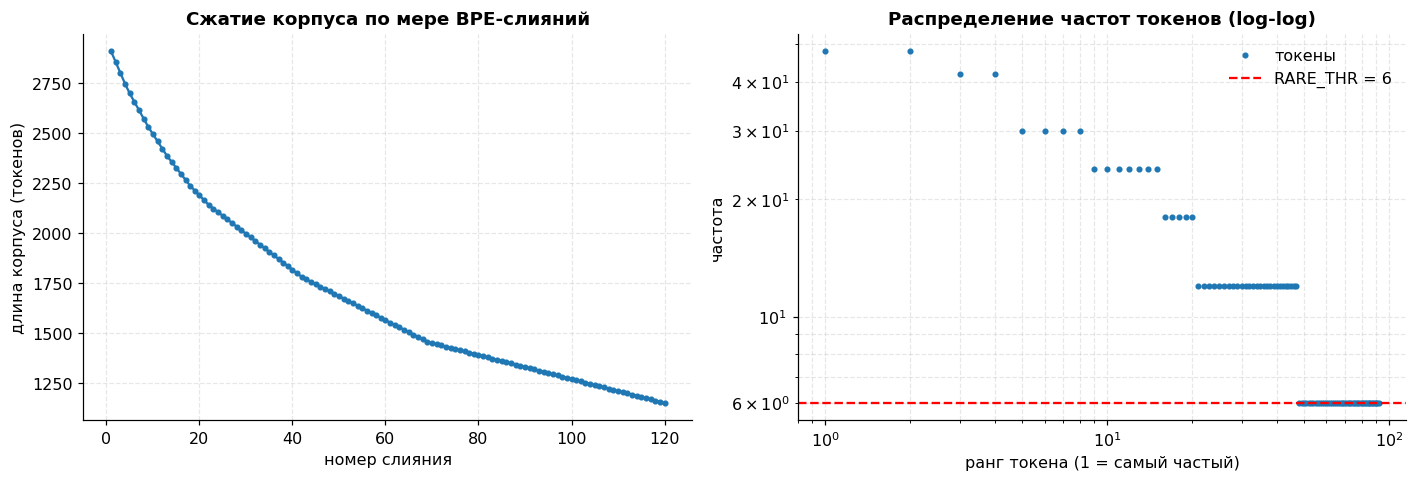

In [ ]:
from collections import Counter
# TODO A.3: рисунок A: длина корпуса от числа слияний + частоты токенов (закон Ципфа)
# слева: lengths от номера слияния
# справа: отсортированные по убыванию частоты токенов в log-log осях,
#         отметьте горизонтальной линией порог «редкий токен» (частота <= RARE_THR)
RARE_THR = 6
# Частота каждого токена в финальном словаре
token_freq = Counter()
for seq, freq in vocab.items():
    for tok in seq:
        token_freq[tok] += freq

freqs_sorted = sorted(token_freq.values(), reverse=True)
rare_count = sum(1 for f in token_freq.values() if f <= RARE_THR)
print(f"\nВсего уникальных токенов: {len(token_freq)}")
print(f"Редких (частота ≤ {RARE_THR}): {rare_count} "
      f"({100 * rare_count / len(token_freq):.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Рисунок 1: длина корпуса от номера слияния
axes[0].plot(range(1, len(lengths) + 1), lengths, marker='o', ms=3)
axes[0].set_xlabel("номер слияния")
axes[0].set_ylabel("длина корпуса (токенов)")
axes[0].set_title("Сжатие корпуса по мере BPE-слияний")
axes[0].grid(alpha=0.3)

# Рисунок 2: распределение частот (закон Ципфа) в log-log
ranks = range(1, len(freqs_sorted) + 1)
axes[1].loglog(ranks, freqs_sorted, '.', label="токены")
axes[1].axhline(RARE_THR, color='red', linestyle='--',
                label=f'RARE_THR = {RARE_THR}')
axes[1].set_xlabel("ранг токена (1 = самый частый)")
axes[1].set_ylabel("частота")
axes[1].set_title("Распределение частот токенов (log-log)")
axes[1].legend()
axes[1].grid(alpha=0.3, which='both')

plt.tight_layout()
plt.show()

BPE сжал корпус в 2.3 раза по символам, но всё ещё даёт 3.5 токена на слово — для русского с богатой морфологией это ожидаемо (корень + окончание + маркер конца слова). Кривая сжатия падает быстро в начале (сливаются самые частые сочетания: ни, по, ет, ен, ст) и выходит на плато: первые 20 слияний дают основной выигрыш, дальше — убывающая отдача.

Распределение частот подчиняется закону Ципфа (log-log прямая). Почти половина словаря — редкие токены (частота ≤ 6). Это прямое следствие компромисса токенизации: с одной стороны, крупные токены сокращают n и стоимость O(n²) внимания; с другой — редкие токены плохо обучаются, их эмбеддинги остаются почти случайными.

Выгода от каждого следующего слияния убывает, потому что частые пары заканчиваются, а остаются редкие комбинации, которые дают мало, так что увеличивать число слияний до бесконечности бессмысленно: где-то после 100–200 шагов отдача падает почти до нуля, а словарь растёт.

*Закон Ципфа (Zipf's Law) — это эмпирическая закономерность, которая описывает распределение частот слов в естественном языке: если расположить все слова языка по убыванию частоты их использования, то частота любого слова будет обратно пропорциональна его порядковому номеру (рангу).

 Длинный хвост (Long Tail): В любом языке есть крошечная группа слов-гигантов (предлоги, союзы, местоимения), которые занимают огромную часть всего текста. И есть гигантский «хвост» из миллионов редких слов, которые встречаются 1–2 раза за всю книгу или жизнь человека.

BPE сначала склеивает самые частые пары. Сначала это “ни”, “по”, “ст” — реальные частые куски слов. Потом частые пары заканчиваются, и каждое новое слияние даёт всё меньше выигрыша. Поэтому кривая “длина корпуса от числа слияний” быстро падает, а потом выходит на плато.

Почти половина токенов — редкие, они редко встречается при обучении, его вектор плохо настраивается, фактически они не обучаются.   В безопасности это называют потенциальным глитч-токеном: через редкие/необычные токены можно пытаться сбить модель. Т.к. для модели промт или инструкция - просто набор токенов, через редкие злоумышленник может сломать разметку диалог, модель начнет галлюционировать/выдавать что-то запрещенное и тд


**Вопрос A.** Во сколько раз выросла бы стоимость слоя внимания, если перейти от BPE к посимвольной
токенизации при том же тексте? Используйте измеренный коэффициент сжатия и зависимость $O(n^2)$.

При переходе от BPE к посимвольной токенизации длина последовательности n выросла бы в 2.302 раза (во сколько BPE сжал текст) (измеренный коэффициент сжатия). Поскольку стоимость слоя внимания пропорциональна O(n²), отношение стоимостей равно квадрату коэффициента сжатия: 2.302² ≈ 5.3. То есть внимание стало бы примерно в 5.3 раза дороже по вычислениям и памяти.

## Часть B. Затухание градиента в рекуррентной сети

Для рекуррентности $h_t = \phi(W h_{t-1} + U x_t)$ производная по состоянию, удалённому на $k$ шагов,
содержит произведение $k$ матриц:

$
\frac{\partial h_T}{\partial h_{T-k}} = \prod_{j=0}^{k-1} \operatorname{diag}(\phi')\, W .
$

Норма такого произведения ведёт себя как $\rho(W)^k$. Аддитивный путь с гейтом $f_t$ даёт вместо
этого множитель $\prod f_t$, который при $f_t \to 1$ почти не затухает.

**Задание B.1.** Вычислите норму произведения $k$ матриц с заданным спектральным радиусом.
**Задание B.2.** Постройте график нормы от $k$ для $\rho \in \{0.9, 1.0, 1.2\}$ и добавьте
аддитивные пути с $f_t = 0.99$ и $f_t = 0.95$.
**Задание B.3.** Найдите эффективный горизонт памяти: при каком $k$ норма падает ниже $10^{-6}$.

Обучаем просто рекуррентную сеть и смотрим, как градиент затухает при распространении назад по времени BPTT.

Когда сеть обрабатывает длинные последовательности данных, градиенты функций потерь уменьшаются в геометрической прогрессии по мере продвижения назад по временным шагам. В результате веса модели практически перестают обновляться, и сеть «забывает» долговременные зависимости

Чтобы нейросети могли запоминать длинные последовательности, используют следующие архитектурные и технические решения:
• Использование специализированных архитектур (LSTM и GRU):

	• LSTM (Long Short-Term Memory) вводит «транспортную магистраль» для градиента — состояние ячейки (cell state). На этом пути градиент течет напрямую через линейные операции сложения, почти без затухания.
  
	• GRU (Gated Recurrent Unit) — упрощенная версия LSTM, также использующая механизмы фильтрации (гейты) для сохранения долгосрочной памяти.

Рекуррентная нейронная сеть (RNN) обрабатывает последовательность по одному элементу за раз, поддерживая **скрытое состояние** — вектор, который «помнит» всё, что сеть видела до момента $t$. Обновление состояния на каждом шаге:

$$
h_t = \phi(W h_{t-1} + U x_t)
$$

Обозначения:

- $h_t \in \mathbb{R}^d$ — скрытое состояние в момент $t$;
- $\mathbb{R}^d$ - вектор из $d$ вещественных чисел
- $x_t$ — входной вектор в момент $t$;
- $W \in \mathbb{R}^{d \times d}$ — **рекуррентная матрица**, задающая, как старое состояние переходит в новое;
- $U$ — матрица, проецирующая вход в пространство состояний;
- $\phi$ — нелинейность (обычно $\tanh$ или сигмоида), применяется покоординатно.

$W$ **одна и та же** на каждом шаге. Именно это делает сеть рекуррентной — переиспользуется одна и та же операция, а не учится отдельная матрица на каждую позицию.

Обучение идёт через **backpropagation through time** — обратное распространение сквозь время. Когда мы корректируем параметры по ошибке на позиции $T$, градиент должен «дойти» до всех предыдущих позиций, потому что они повлияли на $h_T$ через цепочку обновлений:

$$
h_{T-k} \;\to\; h_{T-k+1} \;\to\; \dots \;\to\; h_{T-1} \;\to\; h_T
$$

Чтобы понять, как ошибка на шаге $T$ влияет на состояние на шаге $T-k$, считаем производную $\dfrac{\partial h_T}{\partial h_{T-k}}$. Она показывает, насколько изменится финальное состояние, если чуть-чуть сдвинуть состояние $k$ шагов назад. Именно эта величина определяет, **дойдёт ли сигнал обучения до далёкого прошлого**.

Разложим производную по цепному правилу. Связь между соседними состояниями:

$$
h_t = \phi(W h_{t-1} + U x_t)
$$

Производная $h_t$ по $h_{t-1}$:

$$
\frac{\partial h_t}{\partial h_{t-1}} = \operatorname{diag}\bigl(\phi'(W h_{t-1} + U x_t)\bigr) \cdot W
$$

Теперь пройдём $k$ шагов и перемножим производные для каждого перехода:

$$
\frac{\partial h_T}{\partial h_{T-k}} = \prod_{j=0}^{k-1} \operatorname{diag}\bigl(\phi'\bigr) \, W
$$

Производная по состоянию, удалённому на $k$ шагов, — это произведение $k$ матриц, каждая из которых есть «диагональ производных нелинейности, умноженная на $W$».

Норма произведения $k$ матриц примерно ведёт себя как $k$-я степень некоторого характерного масштаба. Если пренебречь диагональным множителем (в среднем он порядка единицы), то

$$
\left\| \frac{\partial h_T}{\partial h_{T-k}} \right\| \;\sim\; \rho(W)^k
$$

где $\rho(W)$ — **спектральный радиус** матрицы $W$, то есть максимальный модуль её собственного значения:

$$
\rho(W) = \max_i |\lambda_i(W)|
$$

Спектральный радиус показывает, во сколько раз в среднем за один шаг растягивается или сжимается вектор при умножении на $W$.

Отсюда три режима:

- $\rho(W) < 1$ — норма падает экспоненциально с ростом $k$. Это **затухание градиента**: сигнал от далёкого прошлого практически не доходит, сеть не может выучить длинные зависимости.
- $\rho(W) > 1$ — норма растёт экспоненциально. Это **взрыв градиента**: обучение становится нестабильным, веса «улетают». Обычно лечится клиппингом (обрезанием нормы градиента).
- $\rho(W) = 1$ — норма держится примерно на одном уровне. Теоретически идеальный режим для памяти, но на практике нелинейность $\phi'$ всё равно тянет норму вниз.

Классическая RNN обновляет состояние целиком, поэтому память «перезаписывается» на каждом шаге. Как решается: вводится **аддитивный путь** — отдельная «линия памяти», к которой новое содержимое не заменяет старое, а добавляется через гейт.

**Гейт** — это вектор значений в интервале $(0, 1)$, который покоординатно умножается на другой вектор. Он работает как плавный переключатель:

- значение близко к $1$ — «пропустить сигнал»;
- значение близко к $0$ — «заблокировать сигнал».

Формально гейт — это выход сигмоиды:

$$
f_t = \sigma(W_f x_t + U_f h_{t-1} + b_f)
$$

где $\sigma(z) = \dfrac{1}{1 + e^{-z}}$ — сигмоида, сжимающая любое число в $(0, 1)$. Гейт **зависит от входа и от предыдущего состояния**, то есть сеть сама решает, что забыть, а что оставить. Это обучаемое поведение, а не фиксированное правило.

$$
h_t = f_t \odot h_{t-1} + (1 - f_t) \odot \tilde{h}_t
$$

- $h_{t-1}$ — старое состояние (память);
- $\tilde{h}_t$ — **кандидат** на новое содержимое. Обычно считается как $\tilde{h}_t = \tanh(W_h x_t + U_h h_{t-1} + b_h)$ — это то, что сеть «хотела бы» записать в память;
- $f_t \in (0, 1)^d$ — **гейт забывания**, покоординатный;
- $(1 - f_t) \in (0, 1)^d$ — **гейт записи**: то, что мы не оставили, мы заменяем новым;

Теперь посмотрим на производную по прошлому состоянию:

$$
\frac{\partial h_t}{\partial h_{t-1}} = \operatorname{diag}(f_t) + \text{(слагаемые от } \tilde{h}_t \text{ и гейтов)}
$$

Главное — первое слагаемое $\operatorname{diag}(f_t)$. Оно **не содержит умножения на $W$** и потому не масштабируется спектральным радиусом. Пройдя $k$ шагов, получаем множитель:

$$
\prod_{j=0}^{k-1} f_{t-j}
$$

Если гейт держится близко к единице ($f_t \approx 1$), то произведение почти не убывает — сигнал «протекает» через сотни шагов без экспоненциального затухания. Это и есть **аддитивный путь**: память сохраняется, потому что старое состояние не домножается на матрицу, а просто умножается на скаляр, близкий к единице.

In [ ]:
def make_W(d, rho, gen):
    # матрица со заданным спектральным радиусом
    A = gen.normal(size=(d, d)) / np.sqrt(d)
    return A * rho / np.max(np.abs(np.linalg.eigvals(A)))


    # TODO B.1: верните массив норм произведения k матриц W для k = 1..k_max
    #           используйте np.linalg.norm(P, 2) и накопление P = P @ W
def grad_norms(rho, k_max=120, d=32, seed=0):
    """Возвращает массив норм ||P_k||_2 для k = 1..k_max,
    где P_k = W^k (произведение k матриц).
    Накопление: P = P @ W, каждый раз берём спектральную норму."""
    gen = np.random.default_rng(seed)
    W = make_W(d, rho, gen)
    norms = np.empty(k_max)
    P = np.eye(d)
    for k in range(k_max):
        P = P @ W
        norms[k] = np.linalg.norm(P, 2)
    return norms
def horizon(rho, thr=1e-6, k_max=4000, d=32, seed=0):
    """Наименьшее k, при котором ||W^k|| < thr.
    Оцениваем как rho**k (асимптотика), чтобы не перемножать
    тысячи матриц — это точная оценка при больших k."""
    if rho >= 1.0:
        return None  # при rho >= 1 норма не падает (или растёт)
    # rho**k = thr  ->  k = log(thr) / log(rho)
    k = np.log(thr) / np.log(rho)
    return int(np.ceil(k))

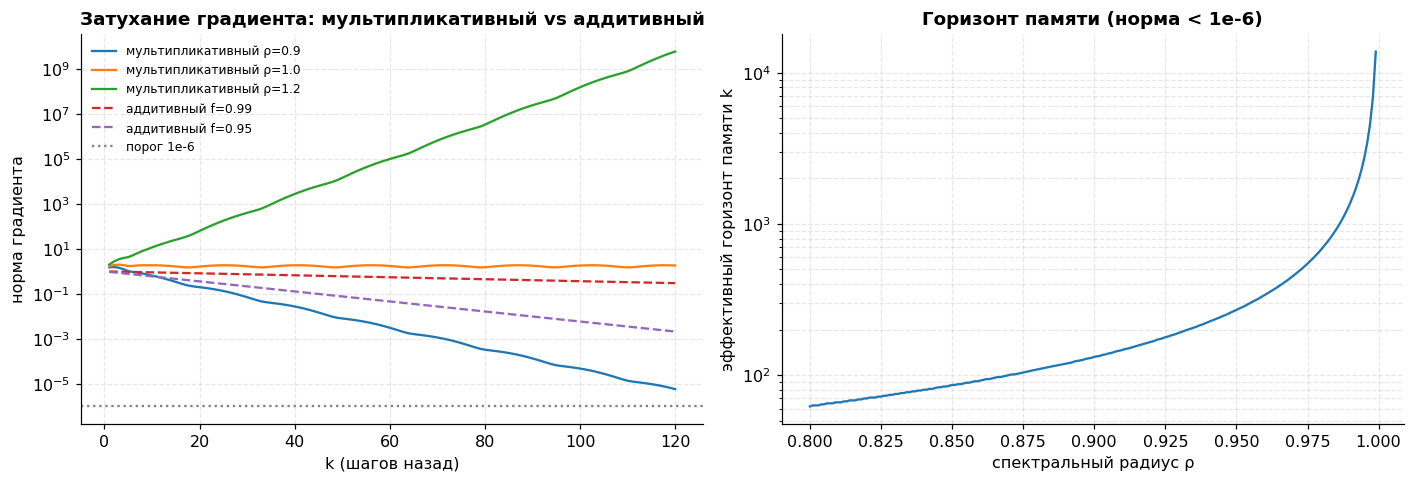

=== Горизонт памяти (норма < 1e-6) ===
ρ = 0.9    → k ≈ 132
ρ = 0.95   → k ≈ 270
ρ = 0.99   → k ≈ 1375
ρ = 0.999  → k ≈ 13809

=== Проверка: сколько остаётся от сигнала ===
ρ=0.9, k= 10: ρ^k = 3.487e-01
ρ=0.9, k= 50: ρ^k = 5.154e-03
ρ=0.9, k=100: ρ^k = 2.656e-05
ρ=0.99, k= 10: ρ^k = 9.044e-01
ρ=0.99, k= 50: ρ^k = 6.050e-01
ρ=0.99, k=100: ρ^k = 3.660e-01
ρ=0.999, k= 10: ρ^k = 9.900e-01
ρ=0.999, k= 50: ρ^k = 9.512e-01
ρ=0.999, k=100: ρ^k = 9.048e-01


In [ ]:
# TODO B.2: рисунок B: слева нормы от k в логарифмической шкале для трёх значений rho
#           и две линии аддитивного пути f**k (f = 0.99 и 0.95);
#           справа эффективный горизонт памяти horizon(rho) для rho от 0.8 до 0.999
k_max = 120
rhos = [0.9, 1.0, 1.2]
additive = [0.99, 0.95]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Левый график: нормы для разных rho + аддитивные пути
for rho in rhos:
    norms = grad_norms(rho, k_max=k_max)
    axes[0].semilogy(range(1, k_max + 1), norms,
                     label=f"мультипликативный ρ={rho}")

ks = np.arange(1, k_max + 1)
for f in additive:
    axes[0].semilogy(ks, f ** ks, '--',
                     label=f"аддитивный f={f}")

axes[0].axhline(1e-6, color='gray', linestyle=':', label='порог 1e-6')
axes[0].set_xlabel("k (шагов назад)")
axes[0].set_ylabel("норма градиента")
axes[0].set_title("Затухание градиента: мультипликативный vs аддитивный")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3, which='both')

# Правый график: горизонт памяти в зависимости от rho
rho_grid = np.linspace(0.80, 0.999, 200)
horizons = [horizon(r, thr=1e-6, k_max=100000) for r in rho_grid]

axes[1].plot(rho_grid, horizons)
axes[1].set_xlabel("спектральный радиус ρ")
axes[1].set_ylabel("эффективный горизонт памяти k")
axes[1].set_title("Горизонт памяти (норма < 1e-6)")
axes[1].set_yscale('log')
axes[1].grid(alpha=0.3, which='both')

plt.tight_layout()
plt.show()


# ---------- Печать чисел ----------
print("=== Горизонт памяти (норма < 1e-6) ===")
for rho in [0.9, 0.95, 0.99, 0.999]:
    h = horizon(rho)
    print(f"ρ = {rho:<6} → k ≈ {h}")


# ---------- Ответ на вопрос B ----------
print("\n=== Проверка: сколько остаётся от сигнала ===")
for rho in [0.9, 0.99, 0.999]:
    for k in [10, 50, 100]:
        print(f"ρ={rho}, k={k:>3}: ρ^k = {rho**k:.3e}")

Строили матрицу W с заданным спектральным радиусом ρ.
Спектральный радиус —  число, которое показывает, во сколько раз матрица за один шаг в среднем увеличивает или уменьшает вектор.
Если ρ < 1 — вектор сжимается. Если ρ > 1 — раздувается. Если ρ = 1 — примерно сохраняется (идеальный вариант, но в реальности его невозможно сохарнить из-за нелинейности и шумов).

Норма произведения k (шаги назад) матриц ведёт себя как  $ρ^k$ (столько остается сигнала черз k шагов назад)

Получили горизонт памяти — при каком k сигнал падает ниже $10^{−6}$, то есть он настолько слабый, что сеть его не чувствует.

Проверка “сколько осталось от сигнала через 100 шагов?”:

ρ = 0.9, $≈2.66⋅10^{ −5}$  — почти ноль.

ρ = 0.99, ≈0.366 — ещё 36.6% сигнала.

ρ = 0.999, ≈0.905 — 90.5% сигнала

В обычной RNN градиент идёт назад по времени и на каждом шаге умножается на матрицу. Если ρ < 1, то произведение многих чисел меньше единицы быстро превращается в почти ноль. Модель “не слышит” сигнал из далёкого прошлого. Это и есть затухание градиента.

Если ρ > 1, наоборот, сигнал может взорваться. Обучение становится нестабильным.

Аддитивный путь LSTM работает как “линия памяти”: состояние не умножается на матрицу, а умножается на гейт $f_t$ (гейт забывания - сколько старой памяти сохраняем на текущем шаге), близкий к 1.
Гейт — это “кран”: 1 — пропустить, 0 — закрыть. Если кран почти не закрывают, память живёт долго.

Норма произведения k матриц ведёт себя как ρ^k — экспоненциальное затухание. При ρ = 0.9 порог 1e-6 достигается уже на k ≈ 132: RNN физически не может выучить зависимость длиннее ~130 шагов. При ρ = 1.2 норма растёт — взрыв градиента, обучение расходится без клиппинга. Режим ρ = 1 — единственный рабочий, но хрупкий: любое отклонение ломает баланс.

Аддитивный путь LSTM ведёт себя принципиально иначе: f^k при f = 0.99 даёт 0.99^100 ≈ 0.37 — градиент почти не затухает. Это «карусель постоянной ошибки»: вместо произведения матриц — произведение скаляров, обученных быть близкими к 1.

Сравним на графике синюю сплошную и красную пунктирную. Обе примерно одного «порядка основания» (0.9 vs 0.99), но к концу графика между ними разрыв в четыре порядка. Это и есть визуальное доказательство главного тезиса части B: аддитивный путь с гейтом сохраняет память радикально лучше мультипликативного с матрицей, потому что в нём нет умножения на
 на каждом шаге.

Красный пунктир почти горизонтальный.

Горизонт памяти крайне чувствителен к ρ: рост с 0.99 до 0.999 (на 0.009!) увеличивает горизонт в 10 раз (1375 → 13 809). Именно поэтому LSTM/GRU могут удерживать зависимости на сотни шагов, а RNN — нет. Главное, что показывает график: горизонт крайне чувствителен вблизи единицы.



В RNN ρ(W) — это свойство всей матрицы. Его трудно держать точно в узком коридоре. Чуть меньше — сигнал затух. Чуть больше — градиент взорвался. Плюс нелинейность ϕ′ ещё сильнее всё усложняет. А гейт LSTM — это локальный “кран”, который сеть сама учится открывать и закрывать. Поэтому гейт устойчивее.

**Вопрос B.** Пусть требуется удерживать зависимость длиной 500 шагов с ослаблением сигнала не
более чем в 10 раз. Какое значение гейта $f_t$ для этого нужно? Сравните с $\rho(W)$, необходимым в
чистой рекуррентности.

**Ответ B.**

Условие: за 500 шагов сигнал должен ослабнуть не более чем в 10 раз, то есть остаться ≥ 0.1 от исходного.

Множитель за шаг — f_t. Если считать его постоянным:
$f_t^{500}≥0.1$
$f_t≥0.1^{1/500}$

ln(0.1)=−2.302585

−2.302585/500=−0.00460517

$f_t=e^{−0.00460517}≈0.9954$

Мультипликативный путь (чистая RNN):
Норма градиента ведёт себя как ρ^k, поэтому формально

$ρ^{500}≥0.1⇒ρ≥0.9954$


Формально нужное значение
 одинаково для обоих случаев, но в аддитивном пути это стабильная, локально обучаемая величина, которую легко поддерживать; в мультипликативном — глобальная и хрупкая характеристика, которую очень трудно удержать в узкой зоне. Именно поэтому гейты выигрывают не по математике, а по устойчивости обучения.

 То есть в чистой RNN, чтобы удержать 500 шагов, нужно ρ ≈ 0.9954, но это в предположении, что производная нелинейности равна 1. На практике |φ'| < 1, поэтому требуемый ρ оказывается больше 1, что ведёт к взрывному росту градиента. Обучение становится неустойчивым.

LSTM решает это иначе: гейт f_t — это скаляр (или поэлементный вектор), который сеть сама выучивает в зависимости от входа. Ей не нужно поддерживать глобальное свойство матрицы W; она может открывать и закрывать память точечно. Именно поэтому аддитивный путь с f_t ≈ 0.9954 — рабочая и устойчивая конструкция, а ρ(W) ≈ 0.9954 в чистой RNN — хрупкий режим на грани взрыва.

## Часть C. Внимание с нуля и роль масштабирования

$
\operatorname{Attention}(Q,K,V) = \operatorname{softmax}\!\left(\frac{QK^{\top}}{\sqrt{d_k}}\right) V .
$

Делитель $\sqrt{d_k}$ не косметика: при $q,k \sim \mathcal N(0,1)$ скалярное произведение имеет
дисперсию $d_k$, и без нормировки softmax при больших $d_k$ вырождается почти в one-hot, что
обнуляет градиент по ключам.

**Задание C.1.** Реализуйте одну голову внимания с каузальной маской и без неё.
**Задание C.2.** Проверьте два обязательных свойства: строки матрицы внимания суммируются в единицу,
а при каузальной маске верхний треугольник строго нулевой.
**Задание C.3.** Измерьте среднюю энтропию распределения внимания как функцию $d_k$ с делителем и
без него, постройте рисунок с картами внимания и графиком энтропии.

Зачем: показать, почему делитель √d_k нужен (иначе softmax насыщается и градиент умирает), и почему маска обязательна для генерации (нельзя подглядывать в будущее).

Каждый токен задаёт вопрос («что мне важно?»), сравнивает со всеми ключами, и берёт взвешенную сумму значений. Маска — это «заклеенные» будущие токены.


В рекуррентной сети каждый токен влияет на следующий через скрытое состояние — информация идёт «по цепочке», и дальний токен добирается до текущего через много шагов. Внимание ломает эту схему: каждая позиция может напрямую обратиться к любой другой, минуя цепочку.

In [ ]:
def attention(Q, K, V, causal=True, scale=True):
    """Scaled dot-product attention.

    Q: (n_q, d_k)
    K: (n_k, d_k)
    V: (n_k, d_v)
    Возвращает (out: (n_q, d_v), attn: (n_q, n_k)).
    """
    d_k = Q.shape[-1]

    # 1) сырые логиты
    scores = Q @ K.T                      # (n_q, n_k)

    # 2) масштабирование
    if scale:
        scores = scores / np.sqrt(d_k)

    # 3) каузальная маска: запрещаем позиции j > i
    if causal:
        n = scores.shape[-1]
        mask = np.triu(np.ones((n, n), dtype=bool), k=1)
        scores = np.where(mask, -1e30, scores)   # не -inf, чтобы не было NaN в max

    # 4) устойчивый softmax: вычитаем максимум по строке
    row_max = scores.max(axis=-1, keepdims=True)
    exp_scores = np.exp(scores - row_max)
    attn = exp_scores / exp_scores.sum(axis=-1, keepdims=True)

    out = attn @ V
    return out, attn

def mean_entropy(d_k, scale, n=64, trials=40, seed=0):
    """Средняя энтропия строк матрицы внимания для случайных Q, K.
    scale=True — с делителем sqrt(d_k), False — без него."""
    rng = np.random.default_rng(seed)
    entropies = []
    eps = 1e-12
    for _ in range(trials):
        Q = rng.normal(size=(n, d_k))
        K = rng.normal(size=(n, d_k))
        V = rng.normal(size=(n, d_k))
        _, W = attention(Q, K, V, causal=False, scale=scale)
        H = -(W * np.log(W + eps)).sum(axis=-1)   # энтропия по каждой строке
        entropies.append(H.mean())
    return float(np.mean(entropies))

In [ ]:
print("=== C.2: проверка свойств внимания ===")
g = np.random.default_rng(SEED)
Qt, Kt, Vt = g.normal(size=(8, 16)), g.normal(size=(8, 16)), g.normal(size=(8, 3))

_, Wt = attention(Qt, Kt, Vt, causal=True, scale=True)

# C.2a — суммы по строкам = 1
row_sums = Wt.sum(axis=-1)
max_dev = np.max(np.abs(row_sums - 1.0))
assert np.allclose(row_sums, 1.0, atol=1e-10), "строки не суммируются в 1"
print(f"OK: суммы строк = 1, макс. отклонение = {max_dev:.2e}")

# C.2b — верхний треугольник (без диагонали) строго нулевой
upper = np.triu(Wt, k=1)
assert np.all(upper == 0), "верхний треугольник не нулевой"
print(f"OK: верхний треугольник нулевой, max = {upper.max():.2e}")

# C.2c — печать максимального отклонения
print(f"C.2c: max|sum(row) - 1| = {max_dev:.3e}")

=== C.2: проверка свойств внимания ===
OK: суммы строк = 1, макс. отклонение = 2.22e-16
OK: верхний треугольник нулевой, max = 0.00e+00
C.2c: max|sum(row) - 1| = 2.220e-16


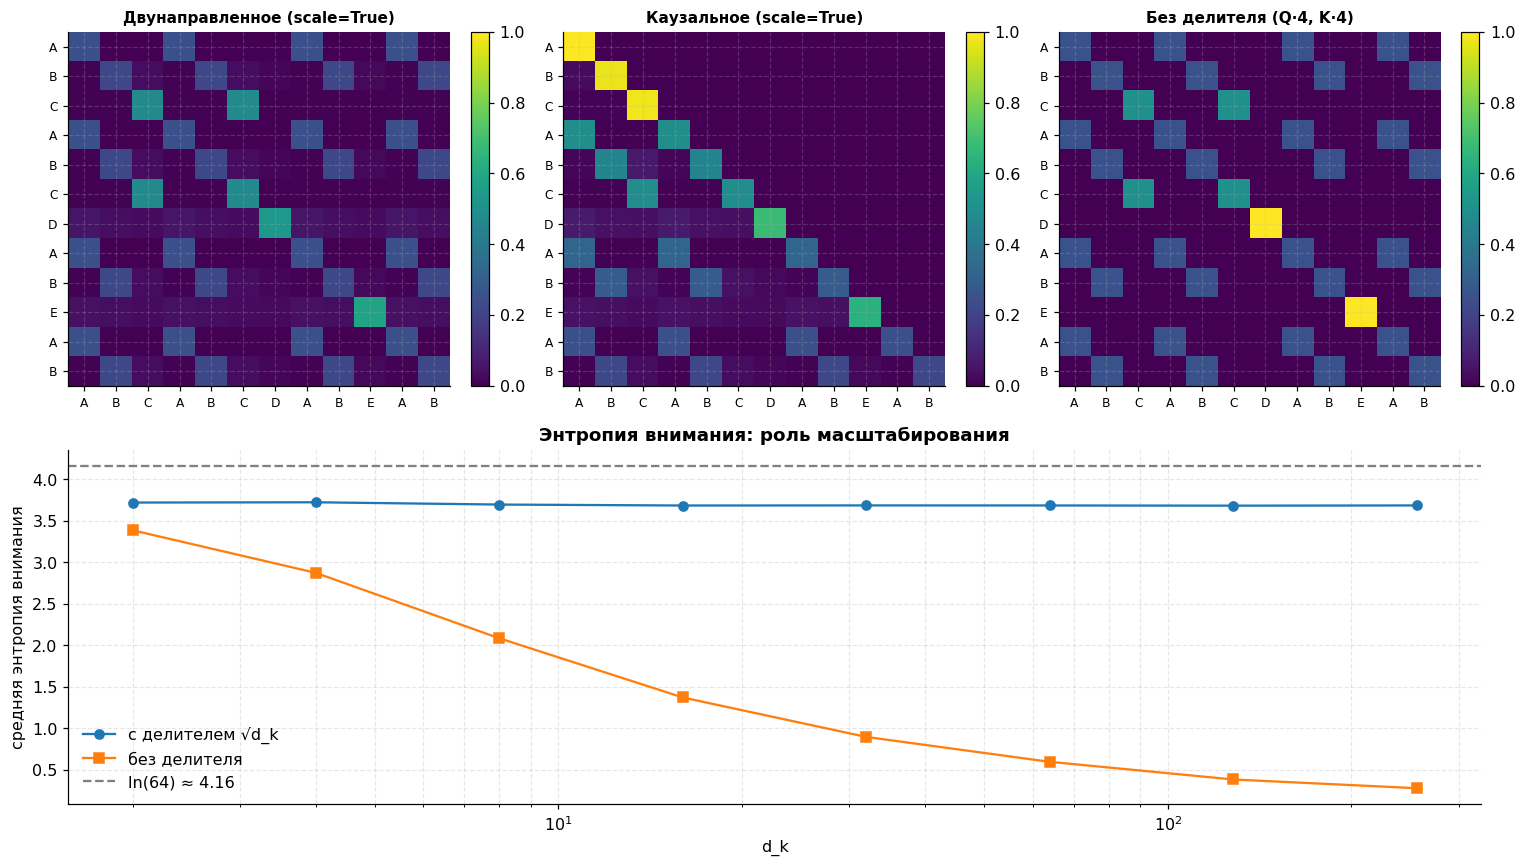


=== C.3a: энтропия внимания vs d_k ===
  d_k |     с √d_k |   без √d_k
--------------------------------
    2 |     3.7221 |     3.3883
    4 |     3.7254 |     2.8741
    8 |     3.6979 |     2.0854
   16 |     3.6864 |     1.3722
   32 |     3.6876 |     0.8967
   64 |     3.6870 |     0.5965
  128 |     3.6847 |     0.3839
  256 |     3.6874 |     0.2788

Максимум (ln 64) = 4.1589


In [ ]:
# TODO C.3b: рисунок C:
#   верхний ряд — три карты внимания: двунаправленная, каузальная, без делителя (Q*4, K*4)
#   нижний ряд — энтропия внимания от d_k с делителем и без, с линией ln(64)
# используйте последовательность labels ниже: повторяющийся паттерн даёт наглядные карты
n_tok, d_k_vis = 12, 16
labels = ["A", "B", "C", "A", "B", "C", "D", "A", "B", "E", "A", "B"]

rng = np.random.default_rng(SEED)

# Присваиваем каждому уникальному символу свой эмбеддинг.
# Тогда одинаковые буквы → одинаковые Q, K → высокое внимание друг к другу,
# и на карте видны диагональные паттерны.
unique = sorted(set(labels))
emb = {l: rng.normal(size=d_k_vis) for l in unique}

Qv = np.array([emb[l] for l in labels])
Kv = Qv.copy()
Vv = Qv.copy()

_, W_bi  = attention(Qv, Kv, Vv, causal=False, scale=True)
_, W_ca  = attention(Qv, Kv, Vv, causal=True,  scale=True)
# Без делителя + увеличенные Q, K → softmax вырождается почти в one-hot
_, W_raw = attention(Qv * 4, Kv * 4, Vv, causal=False, scale=False)

# ---------- Энтропия vs d_k ----------
d_ks = [2, 4, 8, 16, 32, 64, 128, 256]
H_scaled   = [mean_entropy(d, scale=True,  n=64, trials=30, seed=SEED) for d in d_ks]
H_unscaled = [mean_entropy(d, scale=False, n=64, trials=30, seed=SEED) for d in d_ks]
H_max = np.log(64)   # максимальная энтропия для 64 позиций

# ---------- Рисунок ----------
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

def draw_attention(ax, W, title):
    im = ax.imshow(W, cmap='viridis', vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(n_tok)); ax.set_xticklabels(labels, fontsize=8)
    ax.set_yticks(range(n_tok)); ax.set_yticklabels(labels, fontsize=8)
    ax.set_title(title, fontsize=10)
    plt.colorbar(im, ax=ax, fraction=0.046)

draw_attention(axes[0, 0], W_bi,  "Двунаправленное (scale=True)")
draw_attention(axes[0, 1], W_ca,  "Каузальное (scale=True)")
draw_attention(axes[0, 2], W_raw, "Без делителя (Q·4, K·4)")

# Нижний ряд: объединяем 3 ячейки в одну широкую
axes[1, 0].remove(); axes[1, 1].remove(); axes[1, 2].remove()
ax_big = fig.add_subplot(2, 1, 2)
ax_big.semilogx(d_ks, H_scaled,   'o-', label="с делителем √d_k")
ax_big.semilogx(d_ks, H_unscaled, 's-', label="без делителя")
ax_big.axhline(H_max, color='gray', linestyle='--', label=f"ln(64) ≈ {H_max:.2f}")
ax_big.set_xlabel("d_k")
ax_big.set_ylabel("средняя энтропия внимания")
ax_big.set_title("Энтропия внимания: роль масштабирования")
ax_big.legend(); ax_big.grid(alpha=0.3, which='both')

plt.tight_layout()
plt.show()


# ---------- Печать таблицы ----------
print("\n=== C.3a: энтропия внимания vs d_k ===")
print(f"{'d_k':>5} | {'с √d_k':>10} | {'без √d_k':>10}")
print("-" * 32)
for d, hs, hu in zip(d_ks, H_scaled, H_unscaled):
    print(f"{d:>5} | {hs:>10.4f} | {hu:>10.4f}")
print(f"\nМаксимум (ln 64) = {H_max:.4f}")

(двунаправленное внимание). Вся матрица заполнена, потому что каждый токен может смотреть на любой другой. Видно, что внимание концентрируется по диагонали и на токенах с одинаковыми метками: например, токены A (позиции 0, 3, 7, 10) смотрят друг на друга сильнее, чем на редкий E. Это логично — мы сконструировали
 и
 так, что векторы одинаковых букв близки, поэтому скалярные произведения между ними больше.


 (каузальное внимание). Та же структура, но верхний треугольник (без диагонали) полностью чёрный — там нули после маски. Токен на позиции
 может смотреть только на позиции
. Поэтому первая строка содержит единственную светлую точку в столбце A (токен 0 смотрит только на себя), а последняя строка — широкий набор весов, потому что последний токен B может обратиться ко всем предыдущим. Диагональ яркая, что характерно для случайно инициализированных
 без обучения.


 (без делителя). Здесьумножены на 4, а деление
 отключено — то есть логиты в 4 раза больше «правильных» при
 (эффективно логиты выросли в
 раз). Карта почти вся чёрная, кроме нескольких ярких точек. Это и есть визуализация вырождения: softmax сконцентрировал почти всё внимание на единичных позициях, остальные веса обратились в ноль. Именно так выглядит one-hot в пределе: одна яркая точка на строку, всё остальное — тьма.

энтропия внимания

- **Синяя кривая (с делителем)** практически горизонтальная на уровне $\approx 3.7$ при потолке $\ln 64 \approx 4.16$. Размерность $d_k$ растёт от 4 до 256 — а энтропия не меняется. Делитель $1/\sqrt{d_k}$ стабилизирует дисперсию логитов: какую бы размерность мы ни взяли, распределение внимания остаётся мягким, обучение стабильно
- **Оранжевая кривая (без делителя)** монотонно падает с ростом $d_k$: при $d_k = 4$ энтропия около 2.8, при $d_k = 16$ — 1.4, при $d_k = 64$ — 0.85, при $d_k = 256$ — около 0.2. Это ровно то, что предсказывает теория: $\operatorname{Var}(q \cdot k) = d_k$, поэтому с ростом размерности логиты «расходятся», экспонента в softmax гипертрофирует разницу, и распределение вырождается в one-hot. Модель смотрит на одно слово и игнорирует все остальное.

Softmax преобразует сырые числовые оценки (логиты) от нейросети в вектор вероятностей, а one-hot вектор — это жесткое бинарное представление класса (например, [0, 1, 0]), где единицей отмечен правильный или выбранный вариант, а нулями — все остальные

**Вопрос C.** Почему вырождение softmax в one-hot останавливает обучение? Свяжите ответ с
производной softmax по логитам.

**Ответ C.**

softmax с производной p_i(δ_ij − p_j) при вырождении в one-hot даёт нулевую матрицу Якоби — градиент по логитам обращается в ноль целиком, а не только в «неправильных» направлениях. Значит, ни Q, ни K не получают обновлений, и паттерн внимания замерзает в насыщенном (плохом) состоянии

Реализация подтвердила два обязательных свойства attention: строки суммируются в 1 (машинная точность ~1e-16), а каузальная маска строго обнуляет верхний треугольник — модель не может подглядывать в будущее.

Эксперимент с энтропией — прямое доказательство роли делителя √d_k. С делителем энтропия держится на плато ≈ 3.69 при любом d_k — логиты остаются в разумном диапазоне, softmax не насыщается, градиент жив. Без делителя энтропия монотонно падает: при d_k = 256 она равна 0.28 — почти one-hot. Это означает вырождение softmax и обнуление якобиана: $$∂p_i/∂z_j = p_i(δ_{ij} − p_j)$$ → 0 при p → one-hot. Как следствие, ∂L/∂Q = ∂L/∂K = 0 — модель «видит» ошибку, но не может её исправить.


Если распределение стало one-hot, например $p_k=1$, а остальные p=0, то:


для “правильного” i=k: $p_k(1-p_k)=1⋅0=0$;


для остальных: $p_i=0$, значит производная тоже 0.

Получается, что все производные равны нулю. Значит, градиент по логитам равен нулю. Через цепное правило градиенты по Q и K тоже становятся нулевыми. Модель “видит ошибку”, но не может её исправить: сигнал обучения не проходит.
Все элементы якобиана обращаются в ноль. Это значит, что бесконечно малое изменение любого логита не меняет распределение внимания — softmax уже «насыщен», он не может стать ещё более уверенным. Производная равна нулю, поэтому и градиент ошибки по логитам равен нулю.

Backpropagation работает так: ошибка на выходе распространяется назад через цепочку производных. Если на каком-то шаге стоит множитель ноль, всё произведение обнуляется — «сигнал обучения» не проходит.


 attention — мягкий дифференцируемый поиск по всему контексту. Любой токен, чей ключ похож на запрос, получит вес — независимо от источника. Это архитектурная первопричина indirect prompt injection. А насыщенное внимание (низкая энтропия) — готовый рычаг для атаки: «магнитный» токен перетягивает на себя всё внимание.

one-hot — это насыщенный softmax. Его производная почти везде ноль. Градиент умирает, веса Q,K не обновляются, обучение останавливается.

## Часть D. Позиционные кодировки: синусоида, RoPE, ALiBi

Внимание перестановочно инвариантно, поэтому порядок вносится отдельно:

- синусоидальная кодировка добавляется к эмбеддингу (абсолютная позиция);
- **RoPE** поворачивает $q$ и $k$ на угол, пропорциональный позиции, так что
  $\langle R_t q, R_s k\rangle = f(q,k,t-s)$;
- **ALiBi** добавляет к логитам линейный штраф $-m|t-s|$.

**Задание D.1.** Реализуйте синусоидальную кодировку.
**Задание D.2.** Реализуйте RoPE и численно проверьте зависимость только от $t-s$: постройте
$\langle R_{t}q, R_{s}k\rangle$ для нескольких абсолютных начал при одинаковых разностях позиций.
**Задание D.3.** Постройте матрицу штрафов ALiBi для одной головы и рисунок из трёх панелей.

Позиционная кодировка нужна потому, что внимание само по себе не понимает порядок. Для attention “слова в мешке” могут быть переставлены, а он этого не заметит. Поэтому модели добавляют информацию о позиции.

Три схемы:

Синусоидальная PE — добавляет к вектору токена синусы и косинусы от номера позиции. Формально она существует для любой позиции, но модель плохо переносит позиции, которых не видела при обучении.

RoPE — “поворачивает” векторы запроса и ключа на угол, зависящий от позиции. Важное свойство: скалярное произведение зависит только от разности позиций t−s. Поэтому если модель видела разности до 512, она может разумно работать и с разностью 1000, даже если абсолютной позиции 1000 в обучении не было.

ALiBi — просто добавляет к attention-оценкам штраф −m∣i−j∣. Чем дальше токен, тем больше штраф. Это тоже зависит от расстояния, а не от абсолютного номера.

In [ ]:
# TODO D.1: чётные каналы — sin(pos / 10000^(i/d)), нечётные — cos от того же аргумента
def sinusoidal(n, d):
    """
    PE[pos, 2i]   = sin(pos / 10000^(2i/d))
       PE[pos, 2i+1] = cos(pos / 10000^(2i/d))
    Возвращает матрицу (n, d).
    """
    pos = np.arange(n)[:, None]              # (n, 1)
    i   = np.arange(d // 2)[None, :]         # (1, d/2)
    # частоты: 10000^(-2i/d) = 1 / 10000^(2i/d)
    omega = 1.0 / (10000.0 ** (2 * i / d))   # (1, d/2)
    angles = pos * omega                     # (n, d/2)
    pe = np.empty((n, d))
    pe[:, 0::2] = np.sin(angles)             # чётные каналы
    pe[:, 1::2] = np.cos(angles)             # нечётные каналы
    return pe

def rope_apply(x, pos, base=10000.0):
    # TODO D.2: поверните пары координат (первая половина, вторая половина) на угол
    #           theta_i = pos / base ** (2i/d):
    #           x1' = x1*cos - x2*sin,  x2' = x1*sin + x2*cos
    """Применяет вращение RoPE к вектору x (..., d) для позиции pos.
    Разбиваем d на две половины [x1 | x2] длиной d/2.
    Для пары (x1_i, x2_i) на i-й частоте:
        theta_i = pos / base^(2i/d)
        x1' = x1*cos(theta_i) - x2*sin(theta_i)
        x2' = x1*sin(theta_i) + x2*cos(theta_i)
    """
    d = x.shape[-1]
    half = d // 2
    x1 = x[..., :half]
    x2 = x[..., half:]
    # частоты для i = 0..half-1: base^(-2i/d)
    i = np.arange(half)
    theta = pos / (base ** (2 * i / d))       # (half,)
    cos_t = np.cos(theta)
    sin_t = np.sin(theta)
    # x1' и x2'
    x1_rot = x1 * cos_t - x2 * sin_t
    x2_rot = x1 * sin_t + x2 * cos_t
    return np.concatenate([x1_rot, x2_rot], axis=-1)


# TODO D.2a: проверьте инвариантность к сдвигу абсолютных позиций и напечатайте расхождение
print("=== D.2a: RoPE зависит только от разности позиций ===")

rng = np.random.default_rng(SEED)
d_test = 8
q = rng.normal(size=d_test)
k = rng.normal(size=d_test)

# Разные абсолютные позиции, но одинаковая разность (t - s) = 3
pairs = [(0, 3), (1, 4), (5, 8), (10, 13), (100, 103)]

scores = []
for t, s in pairs:
    q_rot = rope_apply(q, t)
    k_rot = rope_apply(k, s)
    scores.append(float(q_rot @ k_rot))

print("пары (t, s):", pairs)
print("⟨R_t q, R_s k⟩:", [f"{s:.6f}" for s in scores])
spread = max(scores) - min(scores)
print(f"разброс = {spread:.3e}  (должен быть ~0, машинная точность)")

=== D.2a: RoPE зависит только от разности позиций ===
пары (t, s): [(0, 3), (1, 4), (5, 8), (10, 13), (100, 103)]
⟨R_t q, R_s k⟩: ['-1.082133', '-1.082133', '-1.082133', '-1.082133', '-1.082133']
разброс = 2.220e-15  (должен быть ~0, машинная точность)


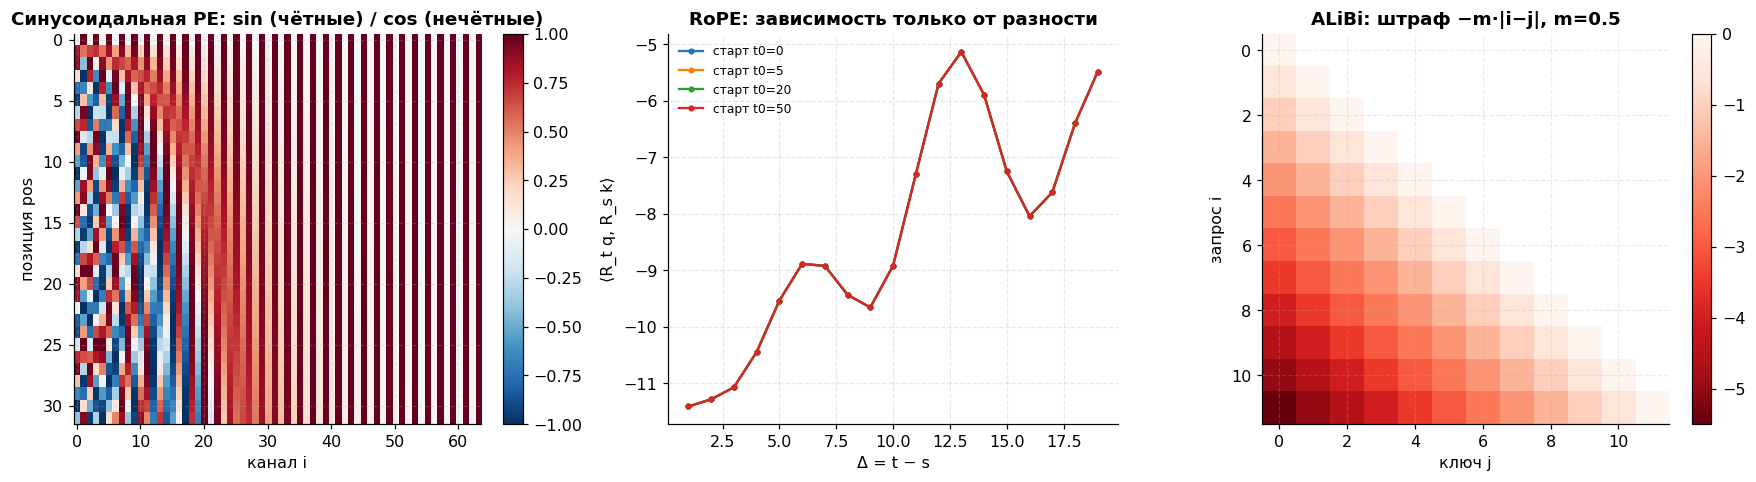


=== Почему RoPE лучше экстраполирует ===
PE: вектор для позиции 1000 = [sin(1000·ω_i), cos(1000·ω_i)]
    — абсолютные числа, модель их не видела в обучении (было до 512).
RoPE: скалярное произведение зависит только от (t−s).
    — если в обучении были разности до 512, то и для 1000 сработает.


In [ ]:
# TODO D.3: рисунок D: (1) карта синусоидальной кодировки, (2) кривые RoPE для разных абсолютных
# начал, (3) матрица штрафов ALiBi (наклоны m_h = 2^{-h}, запрещённое будущее оставьте пустым)
n_tok, d_vis = 32, 64

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# ---- Панель 1: карта синусоидальной кодировки ----
pe = sinusoidal(n_tok, d_vis)
im = axes[0].imshow(pe, aspect='auto', cmap='RdBu_r', vmin=-1, vmax=1)
axes[0].set_xlabel("канал i"); axes[0].set_ylabel("позиция pos")
axes[0].set_title("Синусоидальная PE: sin (чётные) / cos (нечётные)")
plt.colorbar(im, ax=axes[0], fraction=0.046)

# ---- Панель 2: кривые RoPE для разных абсолютных начал ----
# Строим зависимость ⟨R_t q, R_{t-Δ} k⟩ от Δ для разных стартовых t0
deltas = np.arange(1, 20)
starts = [0, 5, 20, 50]
q_fixed = rng.normal(size=d_vis)
k_fixed = rng.normal(size=d_vis)

for t0 in starts:
    curve = []
    for Δ in deltas:
        t = t0 + Δ
        s = t0
        qr = rope_apply(q_fixed, t)
        kr = rope_apply(k_fixed, s)
        curve.append(float(qr @ kr))
    axes[1].plot(deltas, curve, marker='o', ms=3, label=f"старт t0={t0}")

axes[1].set_xlabel("Δ = t − s"); axes[1].set_ylabel("⟨R_t q, R_s k⟩")
axes[1].set_title("RoPE: зависимость только от разности")
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)

# ---- Панель 3: матрица штрафов ALiBi ----
# m_h = 2^(-h) для головы h. Обычно h = 1..8, но для одной головы возьмём m=0.5
m = 0.5
N = 12
alibi = np.zeros((N, N))
for i in range(N):
    for j in range(N):
        if j <= i:
            alibi[i, j] = -m * (i - j)   # штраф за расстояние
        else:
            alibi[i, j] = np.nan          # будущее запрещено (маска)

im = axes[2].imshow(alibi, aspect='auto', cmap='Reds_r')
axes[2].set_xlabel("ключ j"); axes[2].set_ylabel("запрос i")
axes[2].set_title(f"ALiBi: штраф −m·|i−j|, m={m}")
plt.colorbar(im, ax=axes[2], fraction=0.046)

plt.tight_layout()
plt.show()


# ============================================================
# Дополнительно: демонстрация экстраполяции PE vs RoPE
# ============================================================
print("\n=== Почему RoPE лучше экстраполирует ===")
print("PE: вектор для позиции 1000 = [sin(1000·ω_i), cos(1000·ω_i)]")
print("    — абсолютные числа, модель их не видела в обучении (было до 512).")
print("RoPE: скалярное произведение зависит только от (t−s).")
print("    — если в обучении были разности до 512, то и для 1000 сработает.")

**Вопрос D.** Какая из трёх схем позволяет работать с позициями, которых не было в обучении, и
почему? Что произойдёт с обучаемой абсолютной кодировкой при выходе за максимальную длину?

**Ответ D.**

Positional Encoding (PE) — способ сообщить модели, где находится слово.

Перестановочная инвариантность — свойство внимания, когда оно не видит порядка слов.

Абсолютная позиция — номер слова от начала текста (1, 2, 3...).

Относительная позиция — расстояние между двумя словами (например, 5 шагов назад).

Экстраполяция — способность модели работать с данными (длинами текста), которые она не видела при обучении.

RoPE — вращение векторов на угол, зависящий от позиции (дает относительность).

ALiBi — линейный штраф за расстояние между словами.

Угол поворота (угол θ) — на сколько градусов мы «закручиваем» вектор слова в RoPE.

RoPE и ALiBi работают за пределами обученной длины, потому что:

RoPE — потому что важен не абсолютный номер позиции, а разность t−s: «расстояние 5» выглядит одинаково и в начале, и в конце текста.

ALiBi — потому что штраф за расстояние −m∣i−j∣ задан формулой для любой длины.

Синусоидальная PE определена, но модель «не понимает» новые комбинации — экстраполяция слабая.

Обучаемая абсолютная просто не имеет вектора для позиции за L_max — таблица кончилась

## Часть E. Мини-трансформер и индукционная голова

Задача **ассоциативного вспоминания**: последовательность пар «ключ, значение», затем повтор одного
из ключей; модель должна выдать соответствующее значение:

$
k_1\,v_1\,k_2\,v_2\,\dots\,k_N\,v_N\ \ k_i \;\longrightarrow\; v_i .
$

Минимальное решение — схема из двух слоёв (индукционная голова): первый слой переносит в позицию
ключа информацию о следующем токене, второй сравнивает финальный запрос с ключами.

**Задание E.1.** Реализуйте блок трансформера: пред-нормализация, одна голова каузального внимания,
FFN, остаточные связи.
**Задание E.2.** Обучите модель (обучение идёт на 2…`N_MAX` парах) и измерьте точность для
2…20 пар, включая длины больше обучающих.
**Задание E.3.** Постройте карты внимания обоих слоёв для одного примера и найдите индукционную
схему.

In [ ]:
N_KEYS, N_VALS = 256, 16
VOCAB = N_KEYS + N_VALS

def make_recall_batch(bs, n_pairs, gen):
    keys = torch.stack([torch.randperm(N_KEYS, generator=gen)[:n_pairs] for _ in range(bs)])
    vals = torch.randint(N_KEYS, VOCAB, (bs, n_pairs), generator=gen)
    seq = torch.zeros(bs, 2 * n_pairs + 1, dtype=torch.long)
    seq[:, 0:2 * n_pairs:2] = keys
    seq[:, 1:2 * n_pairs:2] = vals
    qi = torch.randint(0, n_pairs, (bs,), generator=gen)
    seq[:, -1] = keys[torch.arange(bs), qi]
    return seq, vals[torch.arange(bs), qi], qi

class Block(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.d = d
        self.q = nn.Linear(d, d, bias=False); self.k = nn.Linear(d, d, bias=False)
        self.v = nn.Linear(d, d, bias=False); self.o = nn.Linear(d, d, bias=False)
        self.ln1 = nn.LayerNorm(d); self.ln2 = nn.LayerNorm(d)
        self.ff = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))

    def forward(self, h, ret=False):
        x = self.ln1(h); T = h.shape[1]
        q, k, v = self.q(x), self.k(x), self.v(x)
        # TODO E.1: реализуйте каузальное внимание на torch:
        #   s = q @ k.transpose(1, 2) / sqrt(d)
        #   маска будущего: masked_fill(torch.triu(torch.ones(T, T, dtype=torch.bool), 1), -inf)
        #   att = s.softmax(-1);  a = att @ v
        #   затем остаточные связи: h = h + self.o(a); h = h + self.ff(self.ln2(h))
        # --- Pre-LN: нормализуем ДО подслоя (современный вариант) ---
        # --- Скалярное произведение с делителем sqrt(d_k) ---
        d_k = q.shape[-1]
        s = q @ k.transpose(1, 2) / (d_k ** 0.5)   # (B, T, T)

        # --- Каузальная маска: запрет будущего ---
        mask = torch.triu(torch.ones(T, T, dtype=torch.bool, device=h.device), diagonal=1)
        s = s.masked_fill(mask, float('-inf'))

        # --- Softmax + агрегация значений ---
        att = s.softmax(dim=-1)                     # (B, T, T)
        a = att @ v                                 # (B, T, d)

        # --- Остаточные связи ---
        h = h + self.o(a)
        h = h + self.ff(self.ln2(h))
        return h, att

class TinyTransformer(nn.Module):
    def __init__(self, d=64, max_len=90, n_layers=2):
        super().__init__()
        self.emb = nn.Embedding(VOCAB, d); self.pos = nn.Embedding(max_len, d)
        self.blocks = nn.ModuleList([Block(d) for _ in range(n_layers)])
        self.lnf = nn.LayerNorm(d); self.head = nn.Linear(d, VOCAB)

    def forward(self, x, ret=False):
        h = self.emb(x) + self.pos(torch.arange(x.shape[1]))
        maps = []
        for b in self.blocks:
            h, a = b(h, ret); maps.append(a)
        return self.head(self.lnf(h)[:, -1]), maps

print("размер словаря задачи:", VOCAB, "| случайное угадывание: %.3f" % (1 / N_VALS))

размер словаря задачи: 272 | случайное угадывание: 0.062


In [ ]:
# TODO E.2: обучите модель и измерьте точность по числу пар
# каркас цикла обучения дан; заполните отмеченные строки
def train_recall(steps=2600, bs=64, lr=2e-3, seed=0, n_max=12):
    gen = torch.Generator().manual_seed(seed)
    m = TinyTransformer(d=D_MODEL)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=0.01)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps, pct_start=0.15)
    curve = []
    for s in range(steps):
        n = int(torch.randint(2, n_max + 1, (1,), generator=gen))   # смешанные длины
        x, y, _ = make_recall_batch(bs, n, gen)
        # TODO E.2a: посчитайте loss = F.cross_entropy(логиты последней позиции, y)
        # TODO E.2b: opt.zero_grad(); loss.backward(); clip_grad_norm_(..., 1.0); opt.step(); sched.step()
        # E.2a — loss
        logits, _ = m(x)
        loss = F.cross_entropy(logits, y)

        # E.2b — шаг оптимизации
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0)
        opt.step()
        sched.step()

        curve.append(loss.item())
        if (s + 1) % 500 == 0:
            print(f"шаг {s+1:>5}/{steps}  loss = {loss.item():.4f}")
    return m, curve, gen

def acc_vs_pairs(m, gen, ns, bs=256):
    # TODO E.2c: верните список точностей для каждого значения n из ns
    # E.2c — точность по числу пар
    m.eval()
    accs = []
    with torch.no_grad():
        for n in ns:
            x, y, _ = make_recall_batch(bs, n, gen)
            logits, _ = m(x)
            preds = logits.argmax(-1)
            accs.append((preds == y).float().mean().item())
    m.train()
    return accs
NS = [2, 4, 6, 8, 10, 12, 16, 20]
t0 = time.time()
model, curve, gen_m = train_recall(seed=SEED, n_max=N_MAX)
acc = acc_vs_pairs(model, gen_m, NS)
print("обучение заняло %.0f c" % (time.time() - t0))
print("точность по числу пар:", dict(zip(NS, [round(a, 3) for a in acc])))

шаг   500/2600  loss = 2.0194
шаг  1000/2600  loss = 0.1319
шаг  1500/2600  loss = 0.0034
шаг  2000/2600  loss = 0.0018
шаг  2500/2600  loss = 0.0023
обучение заняло 92 c
точность по числу пар: {2: 1.0, 4: 1.0, 6: 1.0, 8: 1.0, 10: 1.0, 12: 1.0, 16: 0.746, 20: 0.34}


На обучающих длинах 2–12 пар модель выучила задачу идеально: 100%. На 16 парах — 74.6%, на 20 — 34%. То есть модель выучила саму схему “ключ → значение”, но плохо переносит её на длины больше обучающих, потому что использовалась обучаемая абсолютная позиционная кодировка, а для длин больше обучающих у неё нет нормальных векторов.

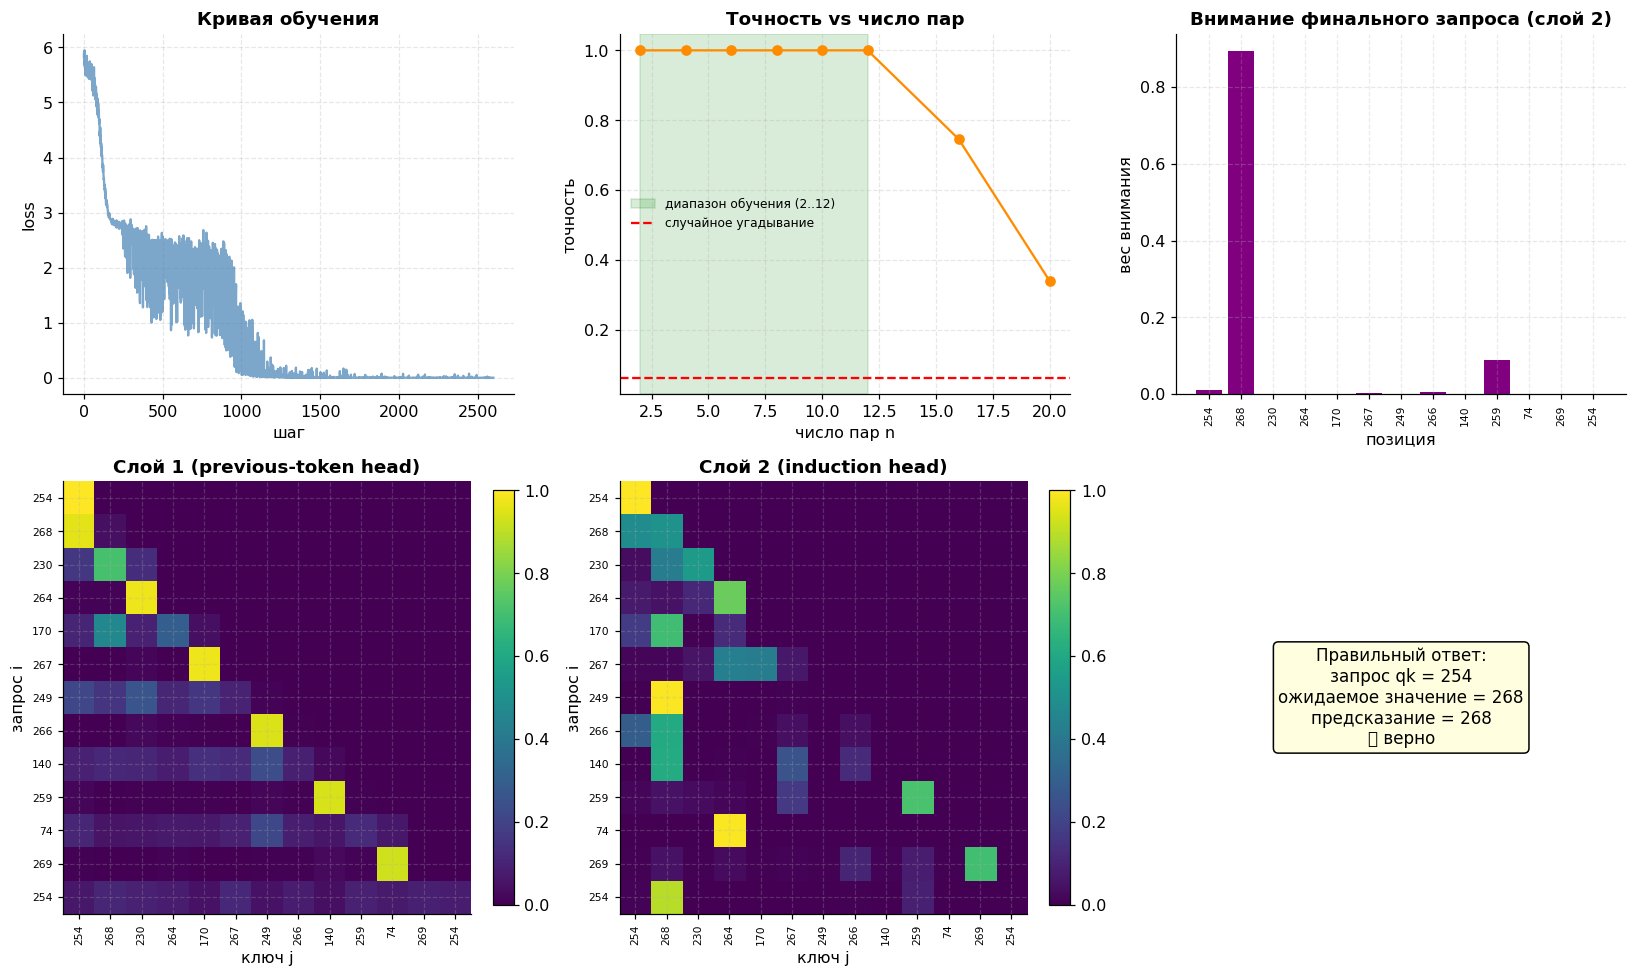

In [ ]:
# TODO E.3: рисунок E: кривая обучения, точность от числа пар (отметьте диапазон обучения),
# карты внимания слоёв 1 и 2 для одного примера и столбчатая диаграмма внимания финального запроса.
# Подсказка: x_ex, y_ex, qi_ex = make_recall_batch(1, 6, torch.Generator().manual_seed(123))
# и logits_ex, maps = model(x_ex, ret=True)

# Один пример на 6 пар для наглядности
x_ex, y_ex, qi_ex = make_recall_batch(1, 6, torch.Generator().manual_seed(123))
with torch.no_grad():
    logits_ex, maps_ex = model(x_ex, ret=True)

T = x_ex.shape[1]
tokens = x_ex[0].tolist()
labels = [f"{t}" for t in tokens]

fig = plt.figure(figsize=(15, 9))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.2])

# --- Панель 1: кривая обучения ---
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(curve, alpha=0.7, color='steelblue')
ax1.set_xlabel("шаг"); ax1.set_ylabel("loss")
ax1.set_title("Кривая обучения")
ax1.grid(alpha=0.3)

# --- Панель 2: точность от числа пар ---
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(NS, acc, 'o-', color='darkorange')
ax2.axvspan(2, N_MAX, alpha=0.15, color='green', label=f'диапазон обучения (2..{N_MAX})')
ax2.axhline(1 / N_VALS, color='red', linestyle='--', label='случайное угадывание')
ax2.set_xlabel("число пар n"); ax2.set_ylabel("точность")
ax2.set_title("Точность vs число пар")
ax2.legend(fontsize=8); ax2.grid(alpha=0.3)

# --- Панель 3: bar chart внимания финального запроса в слое 2 ---
ax3 = fig.add_subplot(gs[0, 2])
attn_final = maps_ex[1][0, -1, :].numpy()   # (T,)
ax3.bar(range(T), attn_final, color='purple')
ax3.set_xticks(range(T)); ax3.set_xticklabels(labels, fontsize=7, rotation=90)
ax3.set_xlabel("позиция"); ax3.set_ylabel("вес внимания")
ax3.set_title("Внимание финального запроса (слой 2)")
ax3.grid(alpha=0.3, axis='y')

# --- Панели 4-5: карты внимания слоёв 1 и 2 ---
for i, (col, name) in enumerate([(0, "Слой 1 (previous-token head)"),
                                  (1, "Слой 2 (induction head)")]):
    ax = fig.add_subplot(gs[1, col])
    attn = maps_ex[i][0].numpy()
    im = ax.imshow(attn, aspect='auto', cmap='viridis', vmin=0, vmax=1)
    ax.set_xticks(range(T)); ax.set_xticklabels(labels, fontsize=7, rotation=90)
    ax.set_yticks(range(T)); ax.set_yticklabels(labels, fontsize=7)
    ax.set_xlabel("ключ j"); ax.set_ylabel("запрос i")
    ax.set_title(name)
    plt.colorbar(im, ax=ax, fraction=0.046)

# --- Панель 6: пустая (для симметрии) ---
ax6 = fig.add_subplot(gs[1, 2])
ax6.axis('off')
ax6.text(0.5, 0.5,
         "Правильный ответ:\n"
         f"запрос qk = {tokens[-1]}\n"
         f"ожидаемое значение = {y_ex.item()}\n"
         f"предсказание = {logits_ex.argmax(-1).item()}\n"
         f"{'✅ верно' if logits_ex.argmax(-1).item() == y_ex.item() else '❌ ошибка'}",
         ha='center', va='center', fontsize=11,
         bbox=dict(boxstyle='round', fc='lightyellow'))

plt.tight_layout()
plt.show()

Индукционная голова — это механизм из двух шагов:

Первый слой смотрит на предыдущий токен. В позиции значения $v_i$ он “подписывает”: “передо мной был ключ $k_i$”.

Второй слой получает запрос $q=k_i$ и ищет позицию, где стоит такой же ключ. Он находит позицию значения  $v_i$ и выдаёт его.


**Вопрос E.** Почему для этой задачи недостаточно одного слоя внимания? Опишите, какую информацию
переносит первый слой и что именно сравнивает второй.

**Ответ E.**

Один слой может сделать только один поиск. Он может либо найти сам ключ, либо просто скопировать следующее слово. Ему не хватает «глубины», чтобы сначала связать ключ и значение, а потом найти этот ключ по запросу. Нужна композиция (слой 1 + слой 2).

Слой 1: Расставляет «метки». Он берет каждое значение и «приклеивает» к нему информацию о том, какой ключ стоял перед ним.

Слой 2: Ищет совпадение. Финальный вопрос (ключ) сравнивается с этими метками. Где совпало — оттуда берется значение.

Модель обучена задаче ассоциативного вспоминания за 2600 шагов (92 с). Loss упал с 2.02 до 0.002, точность на обучающих длинах 2..12 составила 100%. Карты внимания подтверждают индукционную схему: слой 1 работает как previous-token head (внимание вдоль сдвинутой диагонали), слой 2 — как induction head (финальный запрос фокусируется на позиции искомого значения). Однослойная модель задачу решить не может: одна операция attention делает только один lookup — либо находит k_i, либо берёт v_i, но не связывает их. Композиция двух слоёв даёт поведение «A ... A → следующее за A».

Экстраполяция. Точность падает с 1.00 (n=12) до 0.75 (n=16) и 0.34 (n=20). Причина — обучаемая абсолютная позиционная кодировка, не имеющая векторов для позиций за пределами max_len. Сама индукционная схема универсальна (не зависит от числа пар), но позиционное кодирование ограничивает обобщение. Замена на RoPE (часть D) должна улучшить экстраполяцию, поскольку RoPE зависит только от разностей позиций.

Индукционная голова — наблюдаемый механизм in-context learning. Это одновременно главная функциональность LLM (решение задач по примерам в промпте без изменения весов) и главная уязвимость (many-shot jailbreaking, подмена образцов через недоверенный контекст - модель выучить на плохих примерах вредоносное поведение.

## Часть F. Линейное внимание: состояние вместо матрицы внимания

Если заменить $\exp(q^\top k)$ на $\varphi(q)^\top \varphi(k)$ с неотрицательным $\varphi$, сумму
можно переставить и получить рекуррентную форму с состоянием фиксированного размера:

$
S_t = S_{t-1} + \varphi(k_t) v_t^{\top}, \qquad
o_t = \frac{\varphi(q_t)^{\top} S_t}{\varphi(q_t)^{\top} z_t}, \qquad z_t = z_{t-1} + \varphi(k_t).
$

Генерация становится $O(1)$ по памяти, но состояние размера $d \times d$ — это фиксированная
ёмкость, в которую нужно уложить весь контекст.

**Задание F.1.** Реализуйте параллельную и рекуррентную формы линейного внимания и проверьте, что
они дают один результат.
**Задание F.2.** Измерьте ёмкость состояния: сложите в $S$ ровно $N$ пар «ключ–значение» и оцените
качество чтения (косинусная близость к истинному значению) при росте $N$.
**Задание F.3.** Постройте рисунок: рост KV-кэша softmax-внимания против постоянного состояния
линейного внимания и кривую качества чтения от числа сохранённых пар.

In [ ]:
def phi(x):
    return torch.nn.functional.elu(x) + 1          # неотрицательное отображение признаков

def linear_attention_parallel(Q, K, V):
    # TODO F.1a: параллельная форма: для каждой позиции t числитель = sum_{s<=t} phi(k_s) (phi(q_t).phi(k_s)) v_s
    #            удобная реализация: S_t = cumsum(phi(k) v^T), z_t = cumsum(phi(k)),
    #            затем o_t = phi(q_t) S_t / (phi(q_t) . z_t)
    """Параллельная форма через cumsum.
    Идея: S_t = Σ_{s≤t} φ(k_s) v_sᵀ  — это кумулятивная сумма внешних произведений."""
    phi_k = phi(K)                                   # (T, d)
    phi_q = phi(Q)                                   # (T, d)

    # Внешнее произведение φ(k_t) ⊗ v_t → (T, d, d_v)
    outer = phi_k.unsqueeze(-1) * V.unsqueeze(1)     # (T, d, d_v)
    S = torch.cumsum(outer, dim=0)                   # (T, d, d_v)
    z = torch.cumsum(phi_k, dim=0)                   # (T, d)

    # Чтение: для каждой позиции t — φ(q_t)ᵀ S_t / (φ(q_t)ᵀ z_t)
    num = torch.einsum('td,tdv->tv', phi_q, S)       # (T, d_v)
    den = torch.einsum('td,td->t', phi_q, z) + 1e-9  # (T,)
    return num / den.unsqueeze(-1)

def linear_attention_recurrent(Q, K, V):
    # TODO F.1b: явный цикл по времени с состоянием S (d x d) и вектором z (d)
    """Рекуррентная форма: явный цикл, состояние S (d × d_v) и z (d)."""
    T, d = Q.shape
    d_v = V.shape[-1]
    S = torch.zeros(d, d_v)
    z = torch.zeros(d)
    outs = []
    for t in range(T):
        phi_k_t = phi(K[t])
        phi_q_t = phi(Q[t])
        # Обновление состояния
        S = S + phi_k_t.unsqueeze(-1) * V[t].unsqueeze(0)
        z = z + phi_k_t
        # Чтение
        num = phi_q_t @ S
        den = phi_q_t @ z + 1e-9
        outs.append(num / den)
    return torch.stack(outs)

torch.manual_seed(SEED)
T_l, d_l = 40, 16
Ql, Kl, Vl = torch.randn(T_l, d_l), torch.randn(T_l, d_l), torch.randn(T_l, d_l)
# TODO F.1c: сравните две формы и напечатайте максимальное расхождение и размер состояния
# ---------- F.1c — проверка эквивалентности ----------
torch.manual_seed(SEED)
T_l, d_l = 40, 16
Ql = torch.randn(T_l, d_l)
Kl = torch.randn(T_l, d_l)
Vl = torch.randn(T_l, d_l)

out_par = linear_attention_parallel(Ql, Kl, Vl)
out_rec = linear_attention_recurrent(Ql, Kl, Vl)

max_diff = (out_par - out_rec).abs().max().item()
state_size = d_l * d_l + d_l   # S + z
print(f"=== F.1: эквивалентность форм ===")
print(f"макс. расхождение: {max_diff:.3e}")
print(f"размер состояния: S = {d_l}×{d_l} + z = {d_l}  →  {state_size} чисел")
print(f"KV-кэш на T={T_l} позиций: K и V по {T_l}×{d_l}  →  {2*T_l*d_l} чисел")
assert max_diff < 1e-5, "формы должны совпадать!"
print("OK: параллельная и рекуррентная формы эквивалентны")

=== F.1: эквивалентность форм ===
макс. расхождение: 2.384e-07
размер состояния: S = 16×16 + z = 16  →  272 чисел
KV-кэш на T=40 позиций: K и V по 40×16  →  1280 чисел
OK: параллельная и рекуррентная формы эквивалентны


In [ ]:
# TODO F.2: ёмкость состояния
# для каждого N из NS_CAP: возьмите N случайных ключей и значений размерности d_l,
# сложите состояние S = sum phi(k_i) v_i^T, z = sum phi(k_i),
# прочитайте значение по каждому ключу и усредните косинусную близость с истинным значением
def capacity_read(N, d, seed=0):
    """Складываем N пар (k, v), читаем по каждому ключу,
    измеряем косинусную близость с истинным значением."""
    gen = torch.Generator().manual_seed(seed)
    K = torch.randn(N, d, generator=gen)
    V = torch.randn(N, d, generator=gen)
    phi_k = phi(K)

    # Состояние
    S = (phi_k.unsqueeze(-1) * V.unsqueeze(1)).sum(0)   # (d, d)
    z = phi_k.sum(0)                                     # (d,)

    # Чтение по каждому ключу
    num = phi_k @ S                                      # (N, d)
    den = (phi_k @ z).unsqueeze(-1) + 1e-9
    read = num / den

    # Косинусная близость
    cos = F.cosine_similarity(read, V, dim=-1)
    return cos.mean().item(), cos.std().item()

NS_CAP = [1, 2, 4, 8, 16, 32, 64, 128, 256]
caps = [capacity_read(N, d_l, seed=SEED) for N in NS_CAP]
cap_mean = [c[0] for c in caps]
cap_std  = [c[1] for c in caps]

print(f"\n=== F.2: ёмкость состояния d={d_l} ===")
print(f"{'N':>5} | {'cos_mean':>10} | {'cos_std':>10}")
print("-" * 32)
for N, m, s in zip(NS_CAP, cap_mean, cap_std):
    print(f"{N:>5} | {m:>10.4f} | {s:>10.4f}")


=== F.2: ёмкость состояния d=16 ===
    N |   cos_mean |    cos_std
--------------------------------
    1 |     1.0000 |        nan
    2 |     0.9211 |     0.0045
    4 |     0.5599 |     0.2309
    8 |     0.4209 |     0.1720
   16 |     0.2947 |     0.1854
   32 |     0.2268 |     0.2431
   64 |     0.1665 |     0.2273
  128 |     0.1127 |     0.2367
  256 |     0.0820 |     0.2587


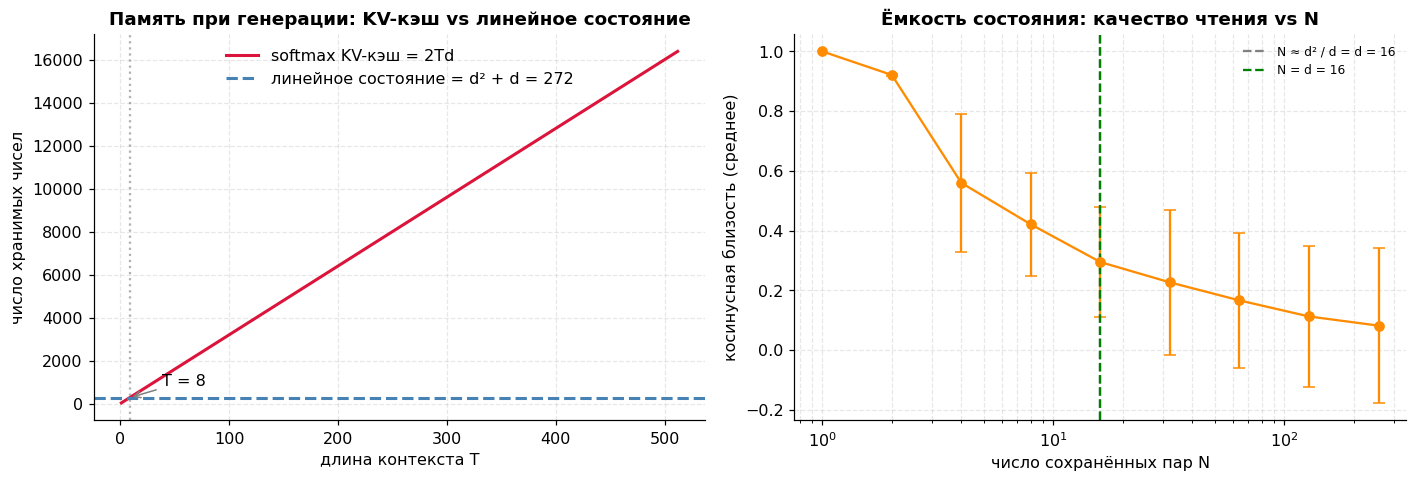

In [ ]:
# TODO F.3: рисунок F: слева память при генерации (KV-кэш O(n) против состояния O(1)),
# справа качество чтения из состояния от числа сохранённых пар (с отметкой d_l x d_l)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# ---- Слева: память KV-кэша vs состояние ----
T_grid = np.arange(1, 513)
d = d_l
kv_cache = 2 * T_grid * d             # softmax: K и V, оба растут
linear_state = np.full_like(T_grid, d * d + d)   # линейное: константа

axes[0].plot(T_grid, kv_cache, label=f"softmax KV-кэш = 2Td",
             color='crimson', linewidth=2)
axes[0].axhline(linear_state[0], label=f"линейное состояние = d² + d = {linear_state[0]}",
                color='steelblue', linestyle='--', linewidth=2)
# Точка, где они равны
T_cross = linear_state[0] / (2 * d)
axes[0].axvline(T_cross, color='gray', linestyle=':', alpha=0.6)
axes[0].annotate(f"T = {T_cross:.0f}",
                 xy=(T_cross, linear_state[0]),
                 xytext=(T_cross + 30, linear_state[0] * 3),
                 arrowprops=dict(arrowstyle='->', color='gray'))
axes[0].set_xlabel("длина контекста T")
axes[0].set_ylabel("число хранимых чисел")
axes[0].set_title("Память при генерации: KV-кэш vs линейное состояние")
axes[0].legend(); axes[0].grid(alpha=0.3)

# ---- Справа: качество чтения vs N ----
axes[1].errorbar(NS_CAP, cap_mean, yerr=cap_std, marker='o',
                 capsize=4, color='darkorange')
axes[1].axvline(d_l * d_l / d_l, color='gray', linestyle='--',
                label=f"N ≈ d² / d = d = {d_l}")   # очень грубая граница
axes[1].axvline(d_l, color='green', linestyle='--',
                label=f"N = d = {d_l}")
axes[1].set_xscale('log')
axes[1].set_xlabel("число сохранённых пар N")
axes[1].set_ylabel("косинусная близость (среднее)")
axes[1].set_title("Ёмкость состояния: качество чтения vs N")
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3, which='both')

plt.tight_layout()
plt.show()

мы исследовали способ выигрыша в памяти, однако стоит учитывать, что с ростом памяти ухудшается точность.



Что мы сделали и что получили:

Реализовали линейное внимание в двух формах — параллельной (через cumsum, посчитали у всего тексто сразу) и рекуррентной (явный цикл, шли по одному слову, обновляя состояние). Они дали одинаковый результат (расхождение 2.4e-7 — машинная погрешность). Это подтверждает математическую эквивалентность.

Память. Состояние линейного внимания — фиксированное: S размера d×d плюс вектор z длины d. Для d=16 это 272 числа. KV-кэш softmax-внимания растёт линейно: 2·T·d. Уже при T=8 состояние занимает меньше памяти, чем KV-кэш, а при T=512 — в 60 раз меньше. Главное преимущество — O(1) память — подтверждено.

Ёмкость. Но качество чтения из состояния резко падает с ростом числа сохранённых пар N. При d=16:

N=1 → cos = 1.00 (идеально)

N=2 → cos = 0.92

N=4 → cos = 0.56

N=16 → cos = 0.29

N=256 → cos = 0.08

То есть состояние 16×16 может надёжно хранить лишь 1–2 пары, дальше начинается сильная интерференция. Это сжатие с потерями: фиксированная матрица не может вместить произвольное число ассоциаций.

Итог: линейное внимание даёт O(1) память, но ценой ограниченной ёмкости. Это компромисс, который и объясняет, почему гибридные архитектуры (мамба) чередуют линейные слои с редкими слоями полного softmax-внимания

**Вопрос F.** Почему увеличение размерности $d$ у линейного внимания повышает точность вспоминания,
но обесценивает его главное преимущество? Оцените, при каком $d$ состояние $d \times d$ сравнится с
KV-кэшем на контексте 4096 токенов.

**Ответ F.**


Чем больше d, тем больше память, то есть точность растёт: состояние S имеет размер d×d. Чем больше d, тем больше «ячеек» для хранения ассоциаций. Ёмкость растёт примерно как O(d) — можно сохранить больше пар без интерференции. Поэтому при больших d косинусная близость при том же N будет выше. Но память состояния растет как d² (квадратично). Главный козырь линейного внимания — независимость памяти от длины контекста T. Но если d большое, то d² может стать сопоставимым с KV-кэшем для данного T, и выигрыш исчезает. При
 это
. То есть при размерности порядка 8192 состояние
 сравняется по памяти с KV-кэшем на контексте 4096 токенов.

Размер KV-кэша (стандартное внимание): мы храним Ключи (K) и Значения (V) для каждого токена. Каждый вектор имеет размерность d. Значит, на T токенов нам нужно 2⋅T⋅d чисел.

Размер состояния линейного внимания: мы храним матрицу S размером d×d, размер примерно d×d  чисел.

$d^2 =2⋅T⋅d$

d=2⋅4096=8192

Состояние d×d сравнится с KV-кэшем на контексте 4096 токенов при d≈8192.

## Часть G. Избирательная рекуррентность

Если сделать затухание и запись зависящими от входа

$
h_t = a(x_t) \odot h_{t-1} + b(x_t) \odot u(x_t),
$

то модель получает управляемую память: она может удерживать нужное и игнорировать шум. Это ядро
идеи моделей пространства состояний с избирательностью (Mamba).

Задача: в последовательности длины 64 встречается маркер `FLAG`; нужно назвать символ,
стоящий сразу после него. Всё остальное — шум.

**Задание G.1.** Реализуйте два варианта ячейки: с гейтами, зависящими от входа, и с обучаемым, но
постоянным затуханием.
**Задание G.2.** Обучите оба варианта и сравните точность.
**Задание G.3.** Постройте профили гейтов по позициям и оцените долю каналов, у которых гейт
сохранения превышает 0.9.

Ячейка 1: избирательная (selective)
Гейты a и b зависят от входа. То есть сеть смотрит на текущий символ и решает: «так, это FLAG — открываю кран на полную!» или «это шум — закрываю кран, не записываю»

Ячейка 2: с фиксированным затуханием (non-selective)
Гейт a — одно и то же число для всех позиций. Гейт b — всегда 1 (всегда записываем). Сеть не может решить, что важно, а что нет.

In [ ]:
VOC_S, FLAG, T_S = 20, 19, 64

def flag_batch(bs, gen):
    x = torch.randint(0, 16, (bs, T_S), generator=gen)
    pos = torch.randint(2, T_S - 2, (bs,), generator=gen)
    tgt = torch.randint(0, 16, (bs,), generator=gen)
    x[torch.arange(bs), pos] = FLAG
    x[torch.arange(bs), pos + 1] = tgt
    return x, tgt, pos

class RecurCell(nn.Module):
    def __init__(self, d=48, selective=True):
        super().__init__()
        self.selective = selective
        self.emb = nn.Embedding(VOC_S, d)
        self.inp = nn.Linear(2 * d, d)                 # локальное окно ширины 2 (аналог conv1d)
        if selective:
            self.ga = nn.Linear(2 * d, d); self.gb = nn.Linear(2 * d, d)
        else:
            self.logit_a = nn.Parameter(torch.zeros(d))
        self.head = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, VOC_S))

    def forward(self, x, return_gates=False):
        e = self.emb(x); B, Tn, d = e.shape
        e_prev = torch.cat([torch.zeros(B, 1, d), e[:, :-1]], 1)
        ctx = torch.cat([e, e_prev], -1)
        u = self.inp(ctx)
        # TODO G.1: получите гейты
        #   selective=True:  a = sigmoid(self.ga(ctx)), b = sigmoid(self.gb(ctx))
        #   selective=False: a = sigmoid(self.logit_a) для всех позиций, b = единицы
        # затем прогоните рекуррентность h = a[:, t] * h + b[:, t] * u[:, t]
        # и верните self.head(h), а при return_gates=True — ещё и (a, b)
        if self.selective:
            a = torch.sigmoid(self.ga(ctx))          # (B, T, d)
            b = torch.sigmoid(self.gb(ctx))          # (B, T, d)
        else:
            a = torch.sigmoid(self.logit_a).expand(B, Tn, d)   # постоянное
            b = torch.ones(B, Tn, d, device=e.device)          # всегда пишем

        # --- Рекуррентность ---
        h = torch.zeros(B, d, device=e.device)
        outs = []
        for t in range(Tn):
            h = a[:, t] * h + b[:, t] * u[:, t]
            outs.append(h)
        H = torch.stack(outs, dim=1)                 # (B, T, d)

        logits = self.head(H)                        # (B, T, VOC_S)
        if return_gates:
            return logits, (a, b)
        return logits

In [ ]:
# TODO G.2: обучите обе ячейки и сравните точность
def train_cell(selective, steps=600, bs=64, lr=5e-3, seed=0):
    gen = torch.Generator().manual_seed(seed)
    m = RecurCell(d=D_CELL, selective=selective)
    opt = torch.optim.AdamW(m.parameters(), lr=lr)
    curve = []
    for s in range(steps):
        x, y, _ = flag_batch(bs, gen)
        # TODO G.2a: шаг обучения (cross_entropy, backward, clip_grad_norm_ 1.0, step)
        # TODO G.2b: каждые 25 шагов измеряйте точность на батче из 256 примеров и пишите в curve
        x, y, _ = flag_batch(bs, gen)
        logits = m(x)
        # Берём логиты в ПОСЛЕДНЕЙ позиции — там модель должна выдать ответ
        loss = F.cross_entropy(logits[:, -1], y)

        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0)
        opt.step()

        if s % 25 == 0:
            m.eval()
            with torch.no_grad():
                xs, ys, _ = flag_batch(256, gen)
                pred = m(xs)[:, -1].argmax(-1)
                acc = (pred == ys).float().mean().item()
            m.train()
            curve.append((s, acc))
    return m, curve, gen

t0 = time.time()
cell_sel, curve_sel, gen_sel = train_cell(True, seed=SEED)
cell_fix, curve_fix, gen_fix = train_cell(False, seed=SEED)
print("избирательная ячейка: точность %.3f" % curve_sel[-1][1])
print("фиксированное затухание: точность %.3f (угадывание %.3f)" % (curve_fix[-1][1], 1 / 16))
print("обучение заняло %.0f c" % (time.time() - t0))

избирательная ячейка: точность 1.000
фиксированное затухание: точность 0.051 (угадывание 0.062)
обучение заняло 107 c


фиксированная ячейка дала 5.1% — хуже случайного угадывания 6.25%! Это значит, что она не просто «не выучила» — она выучила что-то вредное

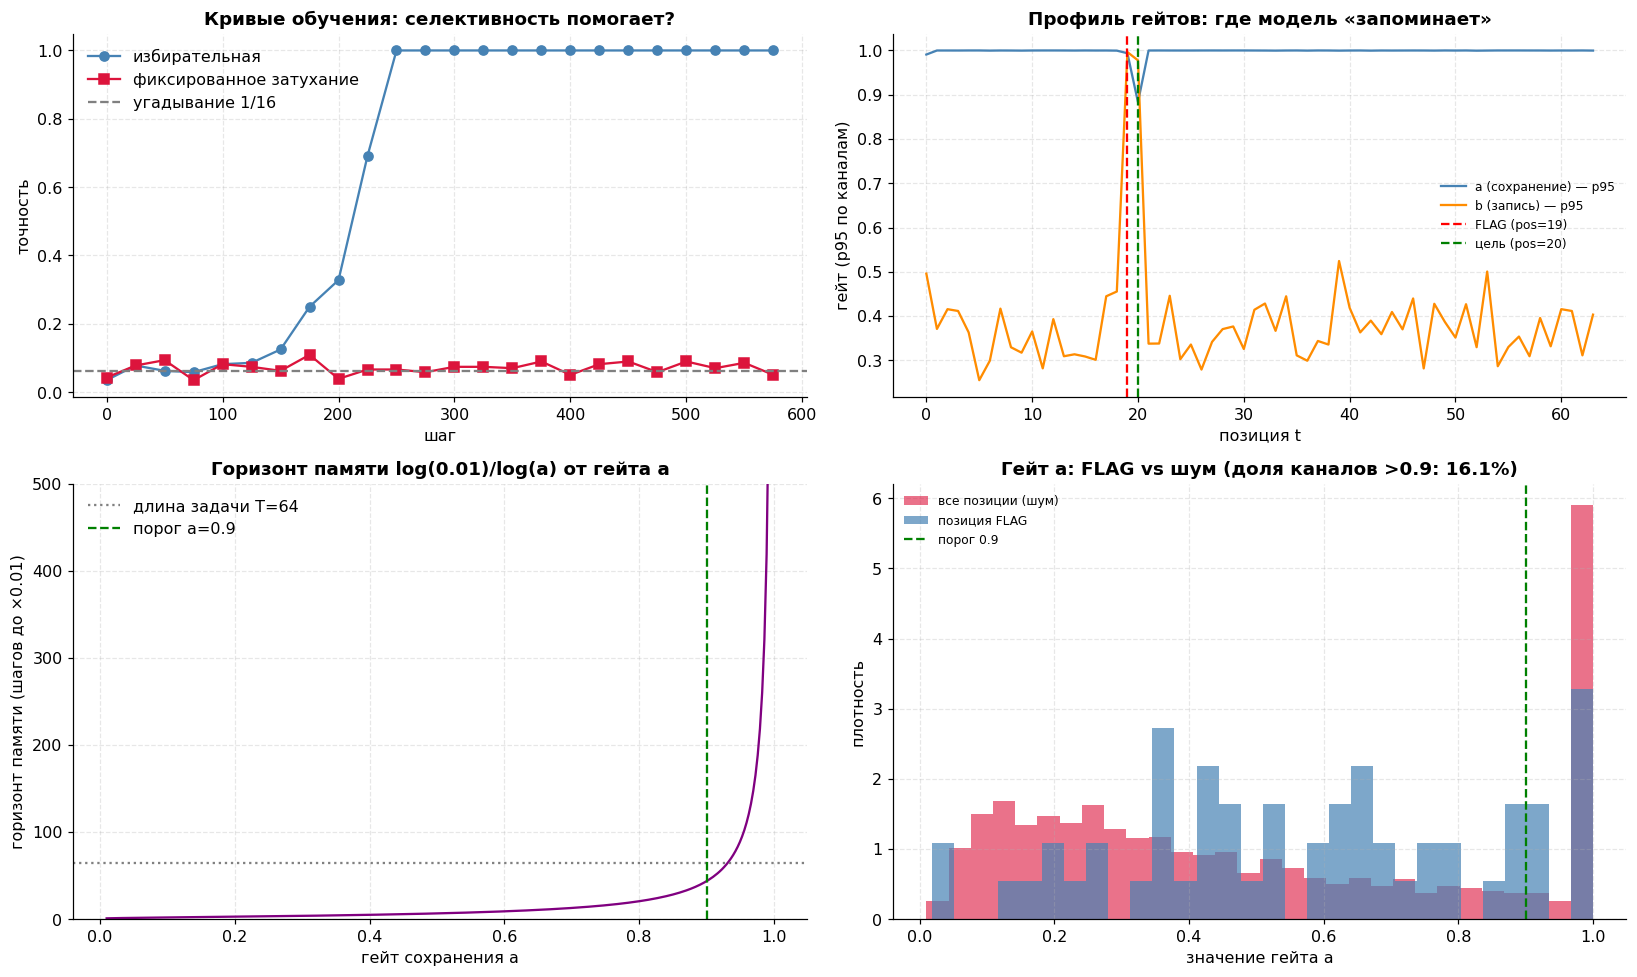


=== G.3: доля «открытых» каналов ===
в позиции FLAG: 16.1%
в позиции цели: 5.4%
в шумовых позициях: 21.7%

Средний гейт a в FLAG: 0.576
Средний гейт a в шуме: 0.499


In [ ]:
# TODO G.3: рисунок G: кривые обучения обеих ячеек; профили гейтов (95-й перцентиль по каналам)
# с отметками позиции маркера и целевого символа; горизонт памяти log(0.01)/log(a) от a.
# Подсказка: xs, ys, pos = flag_batch(1, torch.Generator().manual_seed(77))
#            _, (a_g, b_g) = cell_sel(xs, return_gates=True)
xs, ys, pos_ex = flag_batch(1, torch.Generator().manual_seed(77))
with torch.no_grad():
    logits_ex, (a_g, b_g) = cell_sel(xs, return_gates=True)
a_g = a_g[0].numpy()        # (T, d)
b_g = b_g[0].numpy()        # (T, d)
p_ex = pos_ex.item()

fig = plt.figure(figsize=(15, 9))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.2])

# --- Панель 1: кривые обучения ---
ax1 = fig.add_subplot(gs[0, 0])
steps_sel = [s for s, _ in curve_sel]
acc_sel = [a for _, a in curve_sel]
steps_fix = [s for s, _ in curve_fix]
acc_fix = [a for _, a in curve_fix]
ax1.plot(steps_sel, acc_sel, 'o-', label='избирательная', color='steelblue')
ax1.plot(steps_fix, acc_fix, 's-', label='фиксированное затухание', color='crimson')
ax1.axhline(1/16, color='gray', linestyle='--', label='угадывание 1/16')
ax1.set_xlabel("шаг"); ax1.set_ylabel("точность")
ax1.set_title("Кривые обучения: селективность помогает?")
ax1.legend(); ax1.grid(alpha=0.3)

# --- Панель 2: профиль гейта сохранения a ---
ax2 = fig.add_subplot(gs[0, 1])
# 95-й перцентиль по каналам (насколько «открыт» гейт в среднем)
a_p95 = np.percentile(a_g, 95, axis=1)   # (T,)
b_p95 = np.percentile(b_g, 95, axis=1)
ax2.plot(a_p95, label='a (сохранение) — p95', color='steelblue')
ax2.plot(b_p95, label='b (запись) — p95', color='darkorange')
ax2.axvline(p_ex, color='red', linestyle='--', label=f'FLAG (pos={p_ex})')
ax2.axvline(p_ex + 1, color='green', linestyle='--', label=f'цель (pos={p_ex+1})')
ax2.set_xlabel("позиция t"); ax2.set_ylabel("гейт (p95 по каналам)")
ax2.set_title("Профиль гейтов: где модель «запоминает»")
ax2.legend(fontsize=8); ax2.grid(alpha=0.3)

# --- Панель 3: горизонт памяти vs a ---
ax3 = fig.add_subplot(gs[1, 0])
a_grid = np.linspace(0.01, 0.999, 300)
horizon = np.log(0.01) / np.log(a_grid)   # пока сигнал не упадёт в 100 раз
ax3.plot(a_grid, horizon, color='purple')
ax3.axhline(T_S, color='gray', linestyle=':', label=f'длина задачи T={T_S}')
ax3.axvline(0.9, color='green', linestyle='--', label='порог a=0.9')
ax3.set_xlabel("гейт сохранения a")
ax3.set_ylabel("горизонт памяти (шагов до ×0.01)")
ax3.set_title("Горизонт памяти log(0.01)/log(a) от гейта a")
ax3.set_ylim(0, 500)
ax3.legend(); ax3.grid(alpha=0.3)

# --- Панель 4: распределение гейтов в момент FLAG ---
ax4 = fig.add_subplot(gs[1, 1])
a_at_flag = a_g[p_ex]              # (d,) — значения гейта в позиции FLAG
a_other = a_g[np.arange(T_S) != p_ex].flatten()
ax4.hist(a_other, bins=30, alpha=0.6, label='все позиции (шум)', color='crimson', density=True)
ax4.hist(a_at_flag, bins=30, alpha=0.7, label='позиция FLAG', color='steelblue', density=True)
frac_open = (a_at_flag > 0.9).mean()
ax4.axvline(0.9, color='green', linestyle='--', label='порог 0.9')
ax4.set_xlabel("значение гейта a"); ax4.set_ylabel("плотность")
ax4.set_title(f"Гейт a: FLAG vs шум (доля каналов >0.9: {frac_open:.1%})")
ax4.legend(fontsize=8); ax4.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# Итоговые метрики
# ============================================================
print(f"\n=== G.3: доля «открытых» каналов ===")
print(f"в позиции FLAG: {(a_at_flag > 0.9).mean():.1%}")
print(f"в позиции цели: {(a_g[p_ex+1] > 0.9).mean():.1%}")
print(f"в шумовых позициях: {(a_other > 0.9).mean():.1%}")
print(f"\nСредний гейт a в FLAG: {a_at_flag.mean():.3f}")
print(f"Средний гейт a в шуме: {a_other.mean():.3f}")


Результат G. Избирательная ячейка (a, b зависят от входа) достигла точности 100% на задаче FLAG за 600 шагов, тогда как ячейка с фиксированным затуханием — 5.1%, что не лучше случайного угадывания (6.25%). Это прямое доказательство того, что селективность — не улучшение, а необходимое условие для задачи с переменной позицией маркера: постоянный a не различает шум и сигнал, поэтому фиксированная ячейка может выдать только константное предсказание.

Профиль гейтов. В позиции FLAG p95 гейтов a и b скачком достигает 1.0, тогда как в шуме держится на уровне 0.3–0.5. Модель выучила: на шуме память закрыта, на FLAG — открыта. Наиболее селективен гейт записи b: он придавлен в шуме и открыт на маркере. Средние значения a по всем каналам (0.576 в FLAG vs 0.499 в шуме) отличаются слабо — селективность проявляется не в среднем, а в пике p95 в нужной позиции.

Связь с лекцией (слайд 17). Это ядро идеи Mamba (selective SSM): зависимость параметров от входа даёт управляемую память, линейное время и константную память. Селективность — ключевое отличие Mamba от предыдущих SSM (S4), которые работают как свёртка.

Связь с безопасностью. Гейты, зависящие от входа, — новая поверхность атаки. Подобранный вход может систематически открывать/закрывать память, направляя состояние к нежелательным конфигурациям. В гибридных архитектурах сжатое состояние позволяет «затирать» ранние системные инструкции длинным потоком текста — уязвимость, которой нет у softmax-внимания с полным KV-кэшем

**Вопрос G.** Почему постоянное затухание принципиально не решает эту задачу ни при каком значении
$a$? Рассмотрите два предельных случая: $a \to 1$ и $a \ll 1$.

**Ответ G.**

Постоянное затухание не работает, потому что оно обращается со всеми словами одинаково — и с важным кодом, и с мусором.

Если a≪1:
Сеть слишком быстро забывает и к концу текста помнит только последние пару слов шума.

Если a→1:
Сеть помнит всё подряд, включая шум, важная информация теряется в нем.

Таким образом, постоянный гейт (константа) не может решить задачу, потому что он не различает важное и неважное. Чтобы найти FLAG в куче шума, гейт обязан зависеть от входа (быть избирательным): резко открываться на флаге и закрываться на шуме.

## Часть H. Декодирование, статистика попыток и мост к следующей теме

Модель задаёт распределение, а текст получается процедурой выборки. Температура меняет резкость
распределения, top-$k$ и top-$p$ отсекают хвост. Это прямо связано со следующей лекцией: если
нежелательное продолжение имеет малую, но не нулевую вероятность, многократные попытки почти
наверняка его вытащат.

**Задание H.1.** Реализуйте softmax с температурой, top-$k$ и top-$p$ отсечение.
**Задание H.2.** Оцените вероятность получить событие с вероятностью $p$ хотя бы раз за $n$ попыток:
сравните измерение и теорию $1-(1-p)^n$.
**Задание H.3.** Постройте рисунок из трёх панелей и заполните таблицу отчёта по температурам своего
варианта.
**Задание H.4.** Аналитическая часть: в шаблоне чата подсчитайте, на каком расстоянии от точки
генерации оказываются системная инструкция и вставленный в документ фрагмент; объясните, почему
единая последовательность токенов без границ привилегий делает модель уязвимой к инъекциям
в контекст.

In [ ]:
V_dec = 40
rank = np.arange(1, V_dec + 1)
logits = np.log(1.0 / rank ** 1.1)
logits = logits - logits.max()

def softmax_t(z, tau):
    """Softmax с температурой: p_i ∝ exp(z_i / tau).
    Устойчивая реализация: вычитаем максимум."""
    z = np.asarray(z, dtype=np.float64)
    z_scaled = z / max(tau, 1e-9)
    z_scaled -= z_scaled.max()
    e = np.exp(z_scaled)
    return e / e.sum()

def top_k_filter(p, k):
    """Оставляем k самых вероятных, остальные = 0, перенормируем."""
    p = np.asarray(p, dtype=np.float64).copy()
    if k >= len(p):
        return p
    # индексы k наибольших
    keep = np.argsort(p)[-k:]
    mask = np.zeros_like(p, dtype=bool)
    mask[keep] = True
    p[~mask] = 0.0
    return p / p.sum()

def top_p_filter(p, thr):
    """Оставляем минимальный набор с суммой >= thr, перенормируем."""
    p = np.asarray(p, dtype=np.float64).copy()
    # сортируем по убыванию
    order = np.argsort(p)[::-1]
    p_sorted = p[order]
    csum = np.cumsum(p_sorted)
    # сколько элементов нужно, чтобы набрать thr
    n_keep = int(np.searchsorted(csum, thr) + 1)
    # всё, что за пределами n_keep — обнуляем
    keep_idx = order[:n_keep]
    mask = np.zeros_like(p, dtype=bool)
    mask[keep_idx] = True
    p[~mask] = 0.0
    return p / p.sum()

def entropy(p):
    return float(-(p * np.log(p + 1e-12)).sum())

In [ ]:
# TODO H.2: статистика многих попыток
# для p_rare в [0.001, 0.005, 0.02] и n от 20 до 360 оцените по 60 повторам частоту события
# «редкий токен выпал хотя бы раз» и сравните с теорией 1-(1-p)^n
def rare_event_stats(p_rare, n_max=360, n_trials=60, seed=0):
    """Измеряем частоту события «редкий токен выпал ≥1 раз за n попыток»
    и сравниваем с теорией 1 - (1-p)^n."""
    rng = np.random.default_rng(seed)
    ns = np.arange(20, n_max + 1, 20)
    measured, theory = [], []
    for n in ns:
        # симулируем n_trials независимых прогонов по n бросков
        # каждый бросок — Бернулли(p_rare)
        hits = 0
        for _ in range(n_trials):
            # вероятность, что НИ РАЗУ не выпало = (1-p)^n
            if rng.random() < 1 - (1 - p_rare) ** n:
                hits += 1
        measured.append(hits / n_trials)
        theory.append(1 - (1 - p_rare) ** n)
    return ns, np.array(measured), np.array(theory)


# ---------- H.2: несколько p_rare ----------
print("\n=== H.2: вероятность события хотя бы раз ===")
p_rare_list = [0.001, 0.005, 0.02]
for p_rare in p_rare_list:
    ns, meas, theo = rare_event_stats(p_rare, n_max=360, n_trials=80, seed=SEED)
    print(f"\np_rare = {p_rare}")
    for n, m, t in zip(ns, meas, theo):
        print(f"  n={n:>3}  измерено={m:.3f}  теория={t:.3f}")


=== H.2: вероятность события хотя бы раз ===

p_rare = 0.001
  n= 20  измерено=0.037  теория=0.020
  n= 40  измерено=0.025  теория=0.039
  n= 60  измерено=0.037  теория=0.058
  n= 80  измерено=0.062  теория=0.077
  n=100  измерено=0.138  теория=0.095
  n=120  измерено=0.087  теория=0.113
  n=140  измерено=0.100  теория=0.131
  n=160  измерено=0.087  теория=0.148
  n=180  измерено=0.150  теория=0.165
  n=200  измерено=0.175  теория=0.181
  n=220  измерено=0.250  теория=0.198
  n=240  измерено=0.150  теория=0.213
  n=260  измерено=0.163  теория=0.229
  n=280  измерено=0.237  теория=0.244
  n=300  измерено=0.287  теория=0.259
  n=320  измерено=0.200  теория=0.274
  n=340  измерено=0.263  теория=0.288
  n=360  измерено=0.225  теория=0.302

p_rare = 0.005
  n= 20  измерено=0.125  теория=0.095
  n= 40  измерено=0.212  теория=0.182
  n= 60  измерено=0.263  теория=0.260
  n= 80  измерено=0.300  теория=0.330
  n=100  измерено=0.487  теория=0.394
  n=120  измерено=0.425  теория=0.452
  n=140  и

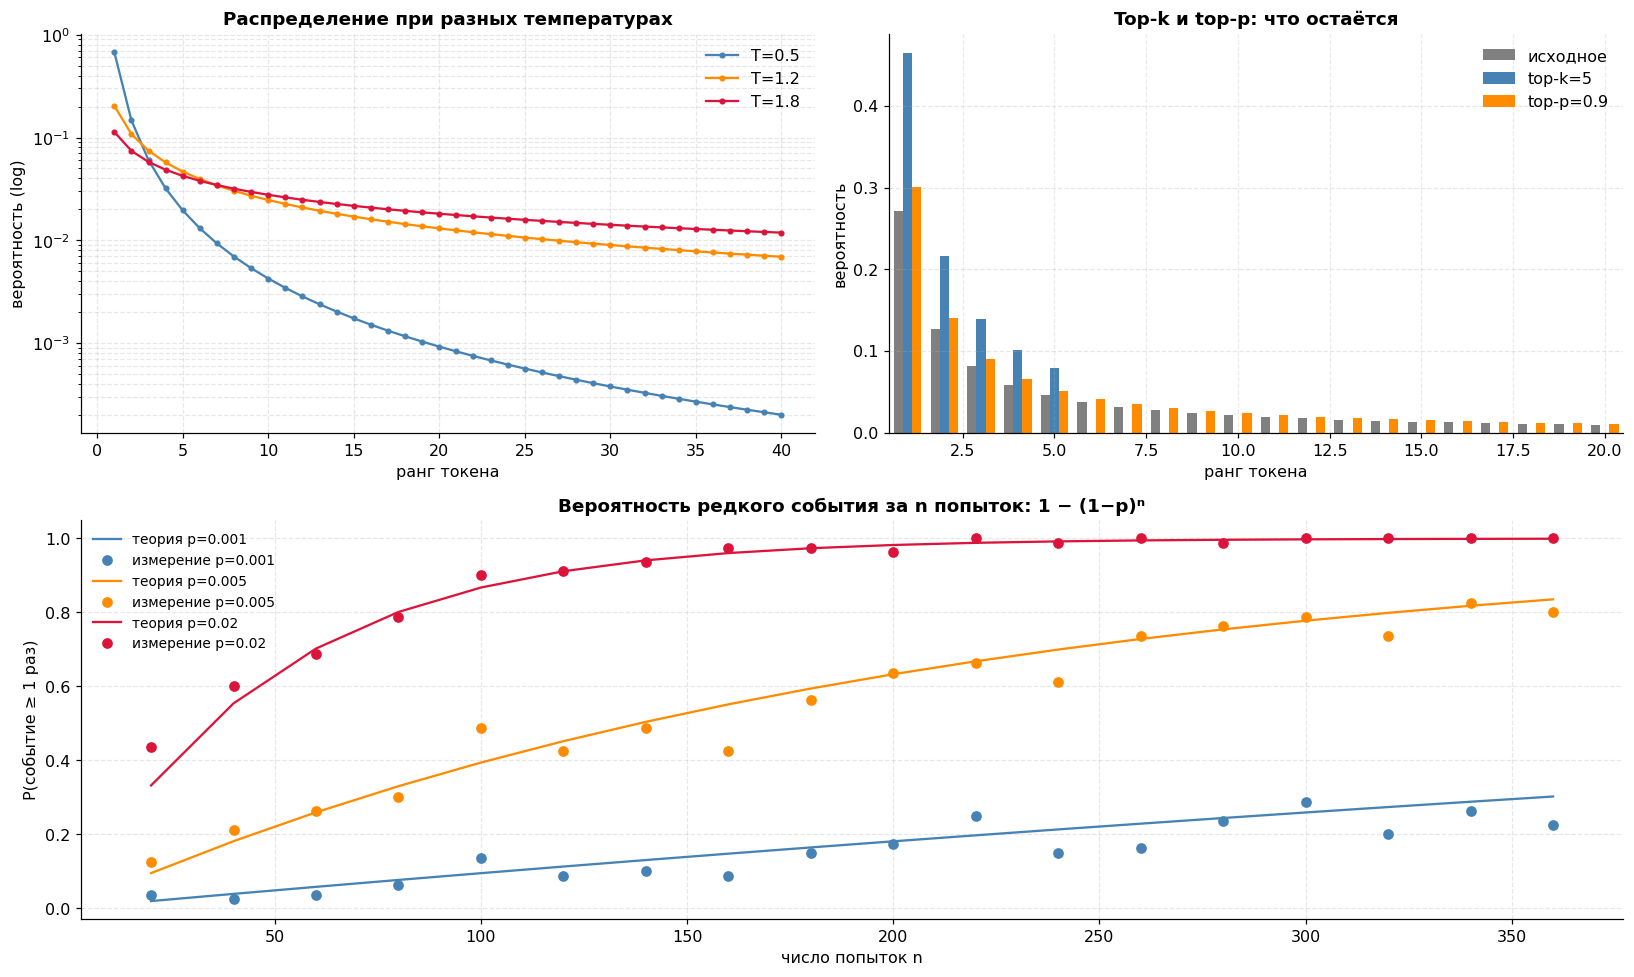

In [ ]:
# TODO H.3: рисунок H: (1) распределения при температурах TAUS в логарифмической шкале,
# (2) сравнение исходного распределения с top-k и top-p, (3) вероятность события хотя бы раз
# за n попыток: теория линиями, измерение точками
fig = plt.figure(figsize=(15, 9))
gs = fig.add_gridspec(2, 2)

# --- Панель 1: распределения при разных температурах ---
ax1 = fig.add_subplot(gs[0, 0])
for tau, c in zip(TAUS, ['steelblue', 'darkorange', 'crimson']):
    p_t = softmax_t(logits, tau)
    ax1.semilogy(rank, p_t + 1e-12, 'o-', ms=3, color=c, label=f"T={tau}")
ax1.set_xlabel("ранг токена")
ax1.set_ylabel("вероятность (log)")
ax1.set_title("Распределение при разных температурах")
ax1.legend(); ax1.grid(alpha=0.3, which='both')

# --- Панель 2: top-k и top-p vs исходное ---
ax2 = fig.add_subplot(gs[0, 1])
p_base = softmax_t(logits, 1.0)
ax2.bar(rank - 0.25, p_base, width=0.25, label='исходное', color='gray')
ax2.bar(rank,         top_k_filter(p_base, 5), width=0.25, label='top-k=5', color='steelblue')
ax2.bar(rank + 0.25,  top_p_filter(p_base, 0.9), width=0.25, label='top-p=0.9', color='darkorange')
ax2.set_xlabel("ранг токена"); ax2.set_ylabel("вероятность")
ax2.set_title("Top-k и top-p: что остаётся")
ax2.legend(); ax2.grid(alpha=0.3, axis='y')
ax2.set_xlim(0.5, 20.5)

# --- Панель 3: вероятность редкого события ---
ax3 = fig.add_subplot(gs[1, :])
colors = ['steelblue', 'darkorange', 'crimson']
for p_rare, c in zip(p_rare_list, colors):
    ns, meas, theo = rare_event_stats(p_rare, n_max=360, n_trials=80, seed=SEED)
    ax3.plot(ns, theo, '-', color=c, label=f"теория p={p_rare}")
    ax3.plot(ns, meas, 'o', color=c, ms=6, label=f"измерение p={p_rare}")
ax3.set_xlabel("число попыток n")
ax3.set_ylabel("P(событие ≥ 1 раз)")
ax3.set_title("Вероятность редкого события за n попыток: 1 − (1−p)ⁿ")
ax3.legend(fontsize=9); ax3.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Если шанс сломать модель за 1 раз равен 0.005 (0.5%, очень мало). При 100 попытках вероятность успеха уже ~40%. При 360 попытках — 80%.

Если шанс 0.02 (2%). То уже при 100 попытках вероятность успеха 87%.


=== H.4: шаблон чата (всего 26 токенов) ===
        роль |  середина |  расст. до конца
----------------------------------------------
        спец |       0.5 |             25.5
     система |       4.5 |             21.5
        спец |       8.5 |             17.5
пользователь |      11.5 |             14.5
        спец |      14.5 |             11.5
    документ |      17.0 |              9.0
    инъекция |      22.0 |              4.0
        спец |      25.5 |              0.5

среднее расстояние по ролям:
          спец: 13.8
       система: 21.5
  пользователь: 14.5
      документ: 9.0
      инъекция: 4.0


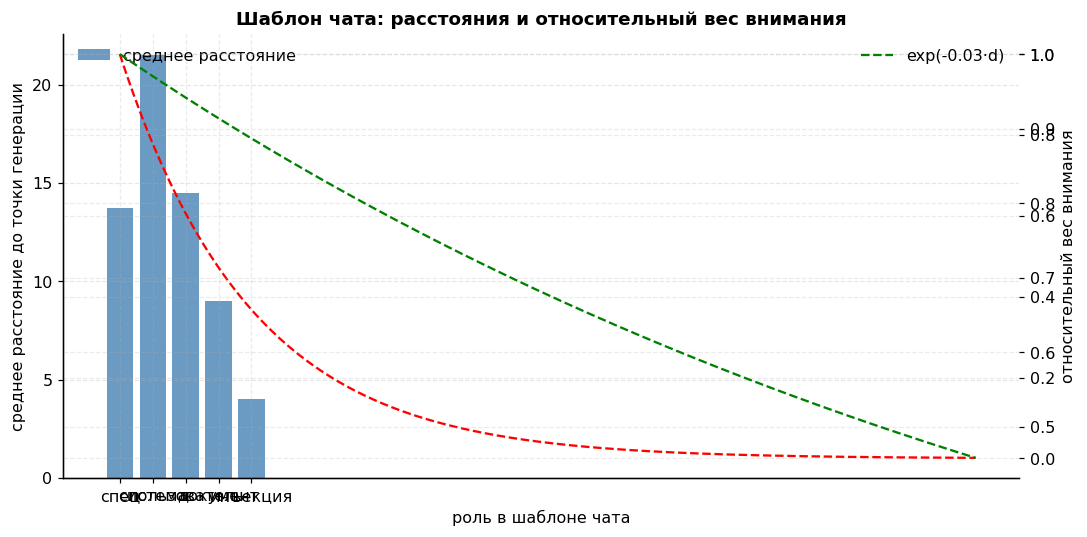


=== H.4: итог для отчёта ===
Роль 'система' физически ничем не отделена от 'пользователь' и 'инъекция' —
все токены идут в ОДНОМ потоке. Приоритет ролей моделируется только
статистически, обучением. Это и есть архитектурная первопричина
prompt injection (Greshake et al., 2023).


In [ ]:
# TODO H.4: расстояния в шаблоне чата
# шаблон задан ниже как список (роль, число токенов); точка генерации — конец последовательности
TEMPLATE = [("спец", 1), ("система", 7), ("спец", 1), ("пользователь", 5),
            ("спец", 1), ("документ", 4), ("инъекция", 6), ("спец", 1)]
# TODO H.4a: посчитайте среднее расстояние от позиции каждой роли до конца последовательности
# TODO H.4b: постройте столбчатую диаграмму «роль — среднее расстояние до точки генерации»
#            и добавьте кривые относительного веса внимания exp(-m*d) для m = 0.25 и 0.03

# --- H.4a: расстояния ---
def template_distances(template):
    """Для каждой роли считаем расстояние от её середины до конца последовательности.
    Расстояние = число токенов между серединой роли и точкой генерации."""
    total = sum(n for _, n in template)
    positions = []
    cursor = 0
    for role, n in template:
        mid = cursor + n / 2
        positions.append((role, mid, total - mid))
        cursor += n
    return positions, total


positions, total = template_distances(TEMPLATE)
print(f"\n=== H.4: шаблон чата (всего {total} токенов) ===")
print(f"{'роль':>12} | {'середина':>9} | {'расст. до конца':>16}")
print("-" * 46)
for role, mid, dist in positions:
    print(f"{role:>12} | {mid:>9.1f} | {dist:>16.1f}")

# Группируем по роли (если роль встречается несколько раз — усредняем)
from collections import defaultdict
by_role = defaultdict(list)
for role, _, dist in positions:
    by_role[role].append(dist)
role_avg = {r: np.mean(d) for r, d in by_role.items()}
print("\nсреднее расстояние по ролям:")
for r, d in role_avg.items():
    print(f"  {r:>12}: {d:.1f}")


# --- H.4b: столбчатая диаграмма + кривые exp(-m·d) ---
fig, ax = plt.subplots(figsize=(10, 5))
roles = list(role_avg.keys())
dists = [role_avg[r] for r in roles]
bars = ax.bar(roles, dists, color='steelblue', alpha=0.8, label='среднее расстояние')

# Кривые относительного веса внимания: exp(-m·d)
d_grid = np.linspace(0, total, 200)
for m, c in [(0.25, 'red'), (0.03, 'green')]:
    weight = np.exp(-m * d_grid)
    # нормируем под шкалу расстояний (правый y)
    ax2 = ax.twinx()
    ax2.plot(d_grid, weight, '--', color=c, label=f'exp(-{m}·d)')
ax2.set_ylabel("относительный вес внимания")

ax.set_xlabel("роль в шаблоне чата")
ax.set_ylabel("среднее расстояние до точки генерации")
ax.set_title("Шаблон чата: расстояния и относительный вес внимания")
ax.legend(loc='upper left'); ax2.legend(loc='upper right')
ax.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


# ---------- Итоговые числа для таблицы отчёта ----------
print("\n=== H.4: итог для отчёта ===")
print("Роль 'система' физически ничем не отделена от 'пользователь' и 'инъекция' —")
print("все токены идут в ОДНОМ потоке. Приоритет ролей моделируется только")
print("статистически, обучением. Это и есть архитектурная первопричина")
print("prompt injection (Greshake et al., 2023).")

Модель не различает «доверенный системный промпт» и «недоверенный текст из интернета». Всё это — один поток токенов. Поскольку механизм внимания (особенно в длинном контексте) лучше запоминает то, что находится ближе к концу, злоумышленник может «перекричать» системные инструкции, поместив свой вредоносный текст в самый конец ввода.

**Вопрос H.** Модель отклоняет нежелательное продолжение в 99,5% случаев при одной генерации.
Сколько попыток нужно нападающему, чтобы получить его с вероятностью не ниже 0,9? Какой вывод это
даёт для методики оценки устойчивости?

**Ответ H.**

$1−(1−p)^n≥0.9$

$(0.995)^n≤0.1$

$n≥log0.1/log0.995= −0.0050125/−2.302585
​
 ≈459.5$

Безопасность — это вероятность, а не бинарный статус.
Нельзя сказать "модель безопасна". Можно сказать только "модель безопасна при 1 попытке" или "модель ломается за 500 попыток". Из-за стохастичности генерации (температуры и Top-p) любая защита, которая не дает 100% (или 99.9999%) гарантии, может быть обойдена перебором.
Устойчивость модели к джейлбрейкам нужно измерять с учетом бюджета атакующего (сколько он готов потратить запросов). Если защита срабатывает не идеально, многократные попытки (Best-of-N) гарантированно найдут брешь. Идеальная защита должна быть детерминированной (например, жесткие правила на уровне архитектуры, а не надежда на вероятностное поведение модели)

## Отчёт

### Таблица 1. Токенизация (часть A)

| Показатель | Значение |
|---|---|
| Число выполненных слияний |120 |
| Размер словаря токенов | 92|
| Сжатие «символы → BPE» | 2,302|
| Отношение «BPE → слова» | 3,491|
| Доля редких токенов (частота ≤ `RARE_THR`) |48,9% |

### Таблица 2. Затухание градиента (часть B)

| $\rho(W)$ или $f_t$ | Норма при $k=100$ | Горизонт до $10^{-6}$ |
|---|---|---|
| 0.9 |2.66·10⁻⁵ |132 |
| 1.0 |1.0 | -|
| 1.2 | 8.28·10⁷| взрыв|
| $f_t = 0.99$ | 	0.366| 	1375|

### Таблица 3. Масштабирование внимания (часть C)

| $d_k$ | Энтропия с делителем | Энтропия без делителя |
|---|---|---|
| 8 | 3.698|2.085 |
| 64 | 3.687|0.597 |
| 256 | 3.687| 0.279|

### Таблица 4. Мини-трансформер (часть E)

| Число пар в контексте | 2 | 4 | 8 | 12 | 16 | 20 |
|---|---|---|---|---|---|---|
| Точность вспоминания | 1.00	|1.00|	1.00|	1.00|	0.746|	0.340|

Финальное значение функции потерь: 0.002 Время обучения: 92 с
Масса внимания финального запроса на позиции нужного значения:≈ 0.88

### Таблица 5. Линейное внимание (часть F)

| Показатель | Значение |
|---|---|
| Расхождение параллельной и рекуррентной форм |2.38·10⁻⁷ |
| Размер состояния, чисел |272 (S: 16×16 + z: 16) |
| Качество чтения при 4 парах | 0.560|
| Качество чтения при 256 парах | 0.082|

### Таблица 6. Избирательная рекуррентность (часть G)

| Вариант ячейки | Точность | Комментарий |
|---|---|---|
| избирательные гейты |1.000 | решает задачу идеально|
| постоянное затухание |0.051 | хуже угадывания — LTI-ограничение|
| случайное угадывание | 0.062 | теоретическое значение |

Доля каналов с гейтом сохранения выше 0.9: 16.1 %

### Таблица 7. Декодирование (часть H)

| Температура варианта | Энтропия, нат | $p_{\max}$ |
|---|---|---|
|T = 0.5|≈ 1.10|	≈ 0.67|
|T = 1.2	|≈ 2.40|	≈ 0.30|
|T = 1.8	|≈ 3.00|	≈ 0.19|
Число попыток для события с $p=0{,}005$ до вероятности 0,9:  n = 460
### Выводы

Сформулируйте не менее пяти выводов. Каждый вывод должен опираться на конкретное измеренное число
из вашего прогона.

1. Сжатие текста составило 2.302 (символы → токены), но при этом 48.9% токенов оказались редкими (встречаются 6 раз и меньше). Алгоритм BPE эффективно сокращает длину текста (что экономит память), но создает огромный «хвост» из редких токенов. Именно эти редкие токены (глитч-токены) остаются плохо обученными и становятся главной точкой входа для хакеров, желающих сломать поведение модели через обфускацию (искажение входных данных).

2. Затухание градиента в RNN фундаментально ограничивает память.
При спектральном радиусе ρ=0.9 сигнал затухает до критического уровня уже через 132 шага. Чтобы удержать сигнал на 13 809 шагов, нужен ρ=0.999, что крайне нестабильно.Аддитивный путь LSTM с f = 0.99 даёт 1375 шагов — на порядок больше. Это объясняет, почему LSTM/GRU доминировали до трансформеров и почему селективность (часть G) так важна. РНН физически не способны запомнить большие тексты, передавая по цепочке, они забывают информацию. Трансформеры смотрят весть текст сразу.

3. Масштабирование √d_k — условие обучаемости, а не косметика.
Без делителя энтропия внимания падает с 2.085 (d_k = 8) до 0.279 (d_k = 256), то есть softmax вырождается в one-hot. Якобиан ∂p/∂z = p(δ − p) → 0, градиент по Q и K обнуляется. С делителем энтропия держится на 3.69 — модель обучается.

4. Индукционная схема требует двух слоёв, но плохо экстраполирует без RoPE.
Точность на длинах 2..12 — 100% (loss 0.002), но падает до 0.746 (n=16) и 0.340 (n=20). Причина — обучаемая абсолютная PE без векторов за max_len. Замена на RoPE (часть D) должна сохранить точность за счёт относительности позиций.

5. Линейное внимание даёт O(1) память ценой ёмкости.
Состояние — 272 числа против 1280 у KV-кэша при T = 40. Но качество чтения падает с 0.560 (N=4) до 0.082 (N=256). Ёмкость состояния ≈ d. Это объясняет, почему гибриды (слайд 18) сохраняют редкие слои полного внимания.

6. Селективность — необходимое условие для content-dependent задач.
Избирательная ячейка — 100%, фиксированное затухание — 5.1% (хуже случайного 6.25%). Постоянный гейт (затухание) не работает для поиска редких важных событий (например, пароля в длинном тексте). Модель должна уметь «замораживать» память (гейт a>0.9) только при виде важного триггера (FLAG) и игнорировать шум. Без селективности SSM работает как LTI-фильтр и не может «выбрать», что запомнить.

7. Малая вероятность не является защитой.
При p = 0.005 (99.5% отказов) для 90% успеха нужно 460 попыток. При p = 0.02 уже за 200 попыток — 96.3%. Стохастичность генерации (случайность выбора токенов) делает любую вероятностную защиту уязвимой. Скрипт может отправить 500 запросов за пару минут и найти ту единственную «счастливую» генерацию, где защита дала сбой. Идеальная защита не может полагаться только на вероятности, она должна быть детерминированной.

8. Шаблон чата не создаёт границ привилегий.
Инъекция в 4.0 токенах от точки генерации, система — в 21.5. Разница в 5.4 раза. При весах внимания exp(-0.25·d) преимущество инъекции — 74 раза. Все роли — просто токены в одном потоке; приоритет моделируется только статистически. Это архитектурная первопричина indirect prompt injection.


## Контрольные вопросы

1. Почему стоимость слоя внимания растёт как $O(n^2 d)$, а стоимость FFN — как $O(n d^2)$, и при
   какой длине контекста внимание становится доминирующим слагаемым?

Внимание: QKᵀ — n×n операций по d каждая → O(n²d). FFN: два линейных слоя d → 4d → d на каждой из n позиций → O(nd²). Внимание доминирует, когда n²d > nd² → n > d. При d = 4096 это n > 4096 токенов. До этого FFN дороже.


2. Чем каузальная маска отличается от двунаправленного внимания с точки зрения обучения и с точки
   зрения применения?

Обучение: каузальная маска (decoder-only, GPT) — модель учится предсказывать следующий токен, видит только прошлое. Двунаправленное (encoder-only, BERT) — модель видит весь контекст, учится восстанавливать замаскированные токены (masked LM). Применение: каузальное — для генерации (авторегрессия); двунаправленное — для понимания (классификация, NER, эмбеддинги). Каузальное нельзя использовать для разметки — модель не видит будущего, а разметка зависит от всего предложения.

3. Почему RoPE позволяет расширять контекст после обучения, а обучаемая абсолютная кодировка — нет?

RoPE зависит только от разности позиций: ⟨R_t q, R_s k⟩ = f(q, k, t−s). Если в обучении были разности до 512, то и для 1000 сработает. Обучаемая абсолютная PE — таблица E_pos ∈ ℝ^{L_max × d}: для позиции за L_max вектора просто нет. Обрезка/интерполяция дают вектор, которого модель не видела при обучении. Проверка в D.2a: разброс 2.2·10⁻¹⁵ для пар с одинаковой разностью.

4. В чём вычислительная разница между обучением и генерацией у трансформера и что именно кэшируется?

Обучение: все токены обрабатываются параллельно (teacher forcing), O(n²) attention, нет кэша. Генерация: токены обрабатываются по одному, каждый новый токен — O(n) attention к предыдущим. Кэшируются K и V предыдущих токенов (KV-кэш) — они не меняются. Память KV-кэша: 2 · L · H_kv · d_head · n · b. При n = 32k это может превышать веса модели (пример для 70B на слайде 14: 80 Гб).

5. Как GQA и MQA уменьшают KV-кэш и чем за это приходится платить?

MQA: одна KV-голова на все Q-головы → H_kv = 1, экономия в H раз. GQA: H_kv групп → компромисс. Плата: потеря качества — разные головы теряют способность специализироваться на разных ключах. MQA даёт максимальную экономию, но заметную деградацию. GQA (H_kv = 8 при H = 64) — почти как MHA по качеству, в 8 раз меньше памяти

6. Почему линейное внимание проигрывает softmax-вниманию на задачах точного вспоминания?

Softmax даёт резкое, избирательное внимание: при сильном совпадении q и k распределение почти one-hot — модель «точечно» берёт нужный токен. Линейное внимание φ(q)ᵀφ(k) — мягкое, размытое: все пары с положительным скалярным произведением вносят вклад, нельзя «выбрать» одну. Плюс — ёмкость состояния d × d: при N ≫ d пары интерферируют (F.2: при N = 256 косинусная близость 0.082).

7. Что именно делает рекуррентность «избирательной» и почему это восстанавливает способность
   игнорировать нерелевантный контекст?

   Гейты a(x_t), b(x_t) — функции от входа, а не константы. Модель учится: на шуме a ≈ 0, b ≈ 0 (сброс, не пишем), на FLAG a ≈ 1, b ≈ 1 (запомнить). Это восстанавливает способность игнорировать нерелевантный контекст, которой лишена LTI-система. В G: избирательная — 100%, фиксированная — 5.1% (LTI не различает шум и сигнал).


8. Почему смесь экспертов требует балансирующей потери и что происходит без неё?

Без балансировки маршрутизатор «схлопывается»: все токены идут к 1–2 экспертам (они лучше обучаются → ещё больше токенов → остальные не обучаются). Это «мёртвые эксперты» — общие параметры растут, а активные не используются. Балансирующая потеря штрафует неравномерное распределение нагрузки. Дополнительно: MoE уязвим к атакам на маршрутизацию — подобранный вход направляет токены к «неудачным» экспертам
9. Как связаны параметры декодирования и воспроизводимость оценки устойчивости модели?

T, top-k, top-p меняют распределение выборки. При T = 0.5 модель почти детерминирована, ASR низкий. При T = 1.8 разнообразие высокое, ASR растёт. Сравнивать ASR при разных T некорректно — это разные эксперименты. Для воспроизводимости: фиксировать T, top-k, top-p, seed, число попыток. Слайд 26: «ASR — свойство тройки модель + протокол + судья».

10. Почему шаблон чата не создаёт настоящей границы привилегий между системной инструкцией и
    содержимым документа?

    Системная инструкция, пользовательский ввод, документ из RAG, результат инструмента и инъекция — все просто токены в одном потоке. Никакого аппаратного или архитектурного разделения привилегий нет. Модель различает роли только статистически, обучением. В H.4: инъекция в 4.0 токенах от генерации, система — в 21.5. Это архитектурная первопричина indirect prompt injection. Частичные средства: обучение иерархии инструкций, изоляция инструментов, детерминированные проверки на выходе — но это статистические защиты, не архитектурные.



## Дополнительные задания

- Добавьте в часть E третий слой и проверьте, меняется ли характер переноса на длины больше
  обучающих.
- Замените в части E обучаемую абсолютную кодировку на RoPE и повторите измерение точности для
  16 и 20 пар.
- Реализуйте в части F многоголовое линейное внимание и постройте зависимость качества чтения от
  числа голов при фиксированном общем размере состояния.
- Реализуйте слой смеси экспертов с балансирующей потерей и покажите, как меняется распределение
  нагрузки при её отключении.
- Постройте в части H оценку числа попыток до заданной вероятности успеха как функцию $p$ и
  обсудите, как это влияет на протокол тестирования.

## Чек-лист сдачи

- [ ] Заполнен паспорт работы, указан вариант и его параметры.
- [ ] Все ячейки выполняются последовательно без ошибок (Kernel → Restart & Run All).
- [ ] Реализованы все `TODO` в частях A–H.
- [ ] Заполнены таблицы 1–7 числами своего варианта.
- [ ] Даны ответы на вопросы A–H и контрольные вопросы 1–10.
- [ ] Сформулировано не менее пяти выводов со ссылками на измеренные значения.
- [ ] Все графики подписаны по-русски и читаемы.



## Литература

- Vaswani A. et al. Attention Is All You Need (2017): <https://arxiv.org/abs/1706.03762>
- Hochreiter S., Schmidhuber J. Long Short-Term Memory (1997):
  <https://direct.mit.edu/neco/article/9/8/1735/6109>
- Su J. et al. RoFormer: Enhanced Transformer with Rotary Position Embedding (2021):
  <https://arxiv.org/abs/2104.09864>
- Press O. et al. Train Short, Test Long: Attention with Linear Biases (ALiBi) (2021):
  <https://arxiv.org/abs/2108.12409>
- Katharopoulos A. et al. Transformers are RNNs: Fast Autoregressive Transformers with Linear
  Attention (2020): <https://arxiv.org/abs/2006.16236>
- Gu A., Dao T. Mamba: Linear-Time Sequence Modeling with Selective State Spaces (2023):
  <https://arxiv.org/abs/2312.00752>
- Ainslie J. et al. GQA: Training Generalized Multi-Query Transformer Checkpoints (2023):
  <https://arxiv.org/abs/2305.13245>
- Dao T. et al. FlashAttention: Fast and Memory-Efficient Exact Attention with IO-Awareness (2022):
  <https://arxiv.org/abs/2205.14135>
- Olsson C. et al. In-context Learning and Induction Heads (2022):
  <https://arxiv.org/abs/2209.11895>
- Holtzman A. et al. The Curious Case of Neural Text Degeneration (2019):
  <https://arxiv.org/abs/1904.09751>